## Load Our Dataset and Check PyTorch

In [1]:
from pathlib import Path
import json

import pandas as pd
import numpy as np
import torch


# -----------------------------------
# 1. Dataset location
# -----------------------------------

DATASET_DIR = Path.cwd() / "phase2_dataset_v1"

WINDOW_FILE = DATASET_DIR / "windows.jsonl"
CONFIG_FILE = DATASET_DIR / "config.json"
TRACKS_DIR = DATASET_DIR / "tracks"

assert DATASET_DIR.exists(), "Dataset directory not found!"
assert WINDOW_FILE.exists(), "Window metadata not found!"
assert CONFIG_FILE.exists(), "Dataset configuration not found!"


# -----------------------------------
# 2. Load dataset metadata
# -----------------------------------

dataset_df = pd.read_json(
    WINDOW_FILE,
    orient="records",
    lines=True
)

with open(CONFIG_FILE, "r") as f:
    dataset_config = json.load(f)


# -----------------------------------
# 3. Verify dataset
# -----------------------------------

assert len(dataset_df) == dataset_config["windows"]

assert (
    dataset_df["track_id"].nunique()
    == dataset_config["songs"]
)

assert dataset_df["split_0"].isin(
    ["train", "validation", "test"]
).all()

assert (
    dataset_df.groupby("artist_id")["split_0"]
    .nunique()
    .max()
    == 1
)


# -----------------------------------
# 4. Check PyTorch environment
# -----------------------------------

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")


# -----------------------------------
# 5. Display information
# -----------------------------------

print("PHASE 2 — TRANSFORMER DEVELOPMENT")
print("--------------------------------")

print("Dataset version:", dataset_config["version"])
print("Total songs:", dataset_df["track_id"].nunique())
print("Total windows:", len(dataset_df))

print(
    "Genre-eligible windows:",
    dataset_df["genre_eligible"].sum()
)

print("\nDATASET SPLITS")
print("--------------------------------")
print(dataset_df["split_0"].value_counts())

print("\nPYTORCH ENVIRONMENT")
print("--------------------------------")
print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

print("\nDataset loaded successfully!")

PHASE 2 — TRANSFORMER DEVELOPMENT
--------------------------------
Dataset version: phase2_dataset_v1
Total songs: 449
Total windows: 5357
Genre-eligible windows: 4041

DATASET SPLITS
--------------------------------
split_0
train         2853
test          1425
validation    1079
Name: count, dtype: int64

PYTORCH ENVIRONMENT
--------------------------------
PyTorch version: 2.13.0
Device: mps

Dataset loaded successfully!


In [2]:
from datetime import datetime

print("DATASET SNAPSHOT INFORMATION")
print("--------------------------------")

print("Dataset path:", DATASET_DIR.resolve())

print(
    "Snapshot created:",
    dataset_config.get("created_utc")
)

print(
    "Version:",
    dataset_config.get("version")
)

print(
    "Songs:",
    dataset_config.get("songs")
)

print(
    "Windows:",
    dataset_config.get("windows")
)

print(
    "Tracked JSON files:",
    len(dataset_config.get("file_sha256", {}))
)

print(
    "Actual JSON files:",
    len(list(TRACKS_DIR.rglob("*.json")))
)

print(
    "Config last modified:",
    datetime.fromtimestamp(
        CONFIG_FILE.stat().st_mtime
    )
)

DATASET SNAPSHOT INFORMATION
--------------------------------
Dataset path: /Users/praise/Developer/vocal-harmonization/experiments/pasan/notebooks/phase2_dataset_v1
Snapshot created: 2026-10-18T17:18:58.641429+00:00
Version: phase2_dataset_v1
Songs: 449
Windows: 5357
Tracked JSON files: 1796
Actual JSON files: 1796
Config last modified: 2026-10-18 22:48:58.642263


### Inspect a Training Window

In [3]:
# -----------------------------------
# 1. Select a training window
# -----------------------------------

sample = (
    dataset_df[
        (dataset_df["split_0"] == "train")
        & (dataset_df["genre_eligible"])
    ]
    .sort_values(["track_id", "start_sec"])
    .iloc[0]
)

track_id = sample["track_id"]

start_sec = sample["start_sec"]
end_sec = sample["end_sec"]

track_folder = TRACKS_DIR / track_id


# -----------------------------------
# 2. Load extracted JSON files
# -----------------------------------

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


melody_data = load_json(
    track_folder / "melody" / "combined.json"
)

beats_data = load_json(
    track_folder / "beats" / "beats.json"
)

chords_data = load_json(
    track_folder / "roman" / "submission.json"
)


# -----------------------------------
# 3. Extract events
# -----------------------------------

notes = melody_data["notes"]
beats = beats_data["beats"]
chords = chords_data["events"]


# -----------------------------------
# 4. Select events within the window
# -----------------------------------

window_notes = [
    note for note in notes
    if (
        note["onset_sec"] < end_sec
        and note["offset_sec"] > start_sec
    )
]

window_beats = [
    beat for beat in beats
    if start_sec <= beat["time_sec"] < end_sec
]

window_chords = [
    chord for chord in chords
    if (
        chord["start_sec"] < end_sec
        and chord["end_sec"] > start_sec
    )
]


# -----------------------------------
# 5. Display results
# -----------------------------------

print("SAMPLE TRAINING WINDOW")
print("--------------------------------")
print("Track:", track_id)
print("Start:", round(start_sec, 2))
print("End:", round(end_sec, 2))
print("Duration:", round(end_sec - start_sec, 2))

print("\nEVENT COUNTS")
print("--------------------------------")
print("Melody notes:", len(window_notes))
print("Beat positions:", len(window_beats))
print("Chord events:", len(window_chords))

print("\nMELODY NOTE STRUCTURE")
print("--------------------------------")
print("Available fields:", list(notes[0].keys()))

for note in window_notes[:5]:
    print(note)

print("\nBEAT STRUCTURE")
print("--------------------------------")
print("Available fields:", list(beats[0].keys()))

for beat in window_beats[:5]:
    print(beat)

print("\nCHORD STRUCTURE")
print("--------------------------------")
print("Available fields:", list(chords[0].keys()))

for chord in window_chords[:5]:
    print(chord)

SAMPLE TRAINING WINDOW
--------------------------------
Track: track_0007391
Start: 47.98
End: 63.98
Duration: 16.0

EVENT COUNTS
--------------------------------
Melody notes: 33
Beat positions: 32
Chord events: 5

MELODY NOTE STRUCTURE
--------------------------------
Available fields: ['onset_sec', 'offset_sec', 'midi_pitch', 'midi_pitch_rounded', 'velocity', 'source']
{'onset_sec': 48.53, 'offset_sec': 48.8, 'midi_pitch': 75.046, 'midi_pitch_rounded': 75, 'model_midi_pitch': 63.046, 'velocity': 100, 'source': 'game_vocal'}
{'onset_sec': 48.8, 'offset_sec': 49.16, 'midi_pitch': 74.545, 'midi_pitch_rounded': 75, 'model_midi_pitch': 62.545, 'velocity': 100, 'source': 'game_vocal'}
{'onset_sec': 49.35, 'offset_sec': 49.6, 'midi_pitch': 76.049, 'midi_pitch_rounded': 76, 'model_midi_pitch': 64.049, 'velocity': 100, 'source': 'game_vocal'}
{'onset_sec': 49.6, 'offset_sec': 50.02, 'midi_pitch': 74.033, 'midi_pitch_rounded': 74, 'model_midi_pitch': 62.033, 'velocity': 100, 'source': 'game_v

### Convert Melody Notes into Beat-Relative Features

In [4]:
# -----------------------------------
# 1. Prepare beat boundaries
# -----------------------------------

beat_times = np.array(
    [beat["time_sec"] for beat in window_beats]
    + [end_sec],
    dtype=float
)

# The final boundary is the end of the window.
# For this example, we expect 33 boundaries:
# 32 beat starts + 1 ending boundary.

assert np.all(np.diff(beat_times) > 0)

beat_positions = np.arange(
    len(beat_times),
    dtype=float
)


# -----------------------------------
# 2. Convert seconds to beat positions
# -----------------------------------

def seconds_to_beats(time_sec):
    return float(
        np.interp(
            time_sec,
            beat_times,
            beat_positions
        )
    )


# -----------------------------------
# 3. Get estimated tonic
# -----------------------------------

tonic_pc = int(sample["melody_tonic_pc"])


# -----------------------------------
# 4. Convert each note
# -----------------------------------

melody_features = []

for note in sorted(
    window_notes,
    key=lambda n: n["onset_sec"]
):

    # Clip notes to the current window
    onset_sec = max(
        note["onset_sec"],
        start_sec
    )

    offset_sec = min(
        note["offset_sec"],
        end_sec
    )

    if offset_sec <= onset_sec:
        continue

    # MIDI pitch
    midi_pitch = int(
        note["midi_pitch_rounded"]
    )

    # Pitch class relative to the tonic
    relative_pc = (
        midi_pitch - tonic_pc
    ) % 12

    # Convert timing to musical beats
    onset_beat = seconds_to_beats(
        onset_sec
    )

    offset_beat = seconds_to_beats(
        offset_sec
    )

    duration_beats = (
        offset_beat - onset_beat
    )

    melody_features.append({
        "midi_pitch": midi_pitch,
        "relative_pc": relative_pc,
        "onset_beat": onset_beat,
        "duration_beats": duration_beats,
        "source": note["source"]
    })


# -----------------------------------
# 5. Display results
# -----------------------------------

melody_features_df = pd.DataFrame(
    melody_features
)

print("MELODY FEATURE REPRESENTATION")
print("--------------------------------")

print("Key tonic pitch class:", tonic_pc)

print("Total notes:", len(melody_features_df))

print("Total beats:", len(window_beats))

print("\nFIRST 15 MELODY NOTES")
print("--------------------------------")

display(
    melody_features_df.head(15).round(3)
)


# -----------------------------------
# 6. Basic validation
# -----------------------------------

assert melody_features_df["relative_pc"].between(
    0, 11
).all()

assert (
    melody_features_df["duration_beats"] > 0
).all()

assert melody_features_df["onset_beat"].between(
    0, len(window_beats)
).all()

print("\nFeature validation passed!")

MELODY FEATURE REPRESENTATION
--------------------------------
Key tonic pitch class: 9
Total notes: 33
Total beats: 32

FIRST 15 MELODY NOTES
--------------------------------


,midi_pitch,relative_pc,onset_beat,duration_beats,source
0,75,6,1.020,0.540,game_vocal
1,75,6,1.560,0.744,game_vocal
2,76,7,2.717,0.523,game_vocal
3,74,5,3.240,0.855,game_vocal
4,76,7,4.714,0.563,game_vocal
5,74,5,5.278,0.426,game_vocal
6,76,7,5.704,0.862,game_vocal
7,62,5,8.762,0.643,game_vocal
8,76,7,9.405,0.614,game_vocal
9,74,5,10.019,0.444,game_vocal



Feature validation passed!


In [5]:
# -----------------------------------
# 1. Configuration
# -----------------------------------

MIN_CHORD_OVERLAP = 0.80

beat_targets = []


# -----------------------------------
# 2. Process every beat
# -----------------------------------

for i, beat in enumerate(window_beats):

    beat_start = float(beat_times[i])
    beat_end = float(beat_times[i + 1])

    beat_duration = beat_end - beat_start

    # Store how long each chord overlaps this beat
    chord_durations = {}

    for chord in window_chords:

        overlap_start = max(
            beat_start,
            chord["start_sec"]
        )

        overlap_end = min(
            beat_end,
            chord["end_sec"]
        )

        overlap = max(
            0.0,
            overlap_end - overlap_start
        )

        if overlap <= 0:
            continue

        label = chord.get("basic_label")

        # Ignore unknown or unmapped chords
        if (
            chord.get("mapping_status") != "mapped"
            or label is None
            or label == "N"
        ):
            continue

        chord_durations[label] = (
            chord_durations.get(label, 0.0)
            + overlap
        )

    # -----------------------------------
    # 3. Find dominant chord
    # -----------------------------------

    if chord_durations:

        best_label = max(
            chord_durations,
            key=chord_durations.get
        )

        best_duration = chord_durations[
            best_label
        ]

        overlap_fraction = (
            best_duration / beat_duration
        )

    else:
        best_label = None
        overlap_fraction = 0.0

    # -----------------------------------
    # 4. Apply reliability threshold
    # -----------------------------------

    valid = (
        best_label is not None
        and overlap_fraction >= MIN_CHORD_OVERLAP
    )

    target_label = (
        best_label if valid else None
    )

    beat_targets.append({
        "beat_index": i,
        "beat_in_bar": beat["beat_in_bar"],
        "is_downbeat": beat["is_downbeat"],
        "start_sec": beat_start,
        "end_sec": beat_end,
        "target_chord": target_label,
        "overlap_fraction": overlap_fraction,
        "valid": valid
    })


# -----------------------------------
# 5. Create DataFrame
# -----------------------------------

beat_targets_df = pd.DataFrame(
    beat_targets
)


# -----------------------------------
# 6. Display results
# -----------------------------------

print("BEAT-LEVEL CHORD TARGETS")
print("--------------------------------")

print("Total beats:", len(beat_targets_df))

print(
    "Valid chord targets:",
    beat_targets_df["valid"].sum()
)

print(
    "Masked beats:",
    (~beat_targets_df["valid"]).sum()
)

print("\nFIRST 16 BEATS")
print("--------------------------------")

display(
    beat_targets_df.head(16).round(3)
)


# -----------------------------------
# 7. Chord distribution
# -----------------------------------

print("\nCHORD LABEL DISTRIBUTION")
print("--------------------------------")

display(
    beat_targets_df["target_chord"]
    .value_counts(dropna=False)
)


# -----------------------------------
# 8. Validation
# -----------------------------------

assert len(beat_targets_df) == len(window_beats)

assert (
    beat_targets_df["overlap_fraction"] >= 0
).all()

assert (
    beat_targets_df.loc[
        beat_targets_df["valid"],
        "target_chord"
    ].notna().all()
)

print("\nChord target validation passed!")

BEAT-LEVEL CHORD TARGETS
--------------------------------
Total beats: 32
Valid chord targets: 30
Masked beats: 2

FIRST 16 BEATS
--------------------------------


,beat_index,beat_in_bar,is_downbeat,start_sec,end_sec,target_chord,overlap_fraction,valid
0,0,1,True,47.98,48.52,i:MIN,0.889,True
1,1,2,False,48.52,49.02,i:MIN,1.000,True
2,2,3,False,49.02,49.48,i:MIN,1.000,True
3,3,4,False,49.48,49.98,i:MIN,1.000,True
4,4,1,True,49.98,50.40,i:MIN,1.000,True
5,5,2,False,50.40,50.94,i:MIN,1.000,True
6,6,3,False,50.94,51.40,i:MIN,1.000,True
7,7,4,False,51.40,51.94,i:MIN,1.000,True
8,8,1,True,51.94,52.36,NaN,0.762,False
9,9,2,False,52.36,52.78,bVI:MAJ,1.000,True



CHORD LABEL DISTRIBUTION
--------------------------------


target_chord
i:MIN      16
bVI:MAJ    14
NaN         2
Name: count, dtype: int64


Chord target validation passed!


In [6]:
from collections import Counter
import pandas as pd


# -----------------------------------
# 1. Configuration
# -----------------------------------

MIN_CHORD_OVERLAP = 0.80

SPLITS = ["train", "validation", "test"]

label_counts = {
    split: Counter()
    for split in SPLITS
}

total_beats = Counter()
valid_beats = Counter()


# -----------------------------------
# 2. Process each song
# -----------------------------------

for track_id, song_windows in dataset_df.groupby("track_id"):

    track_folder = TRACKS_DIR / track_id

    beats_data = load_json(
        track_folder / "beats" / "beats.json"
    )

    chords_data = load_json(
        track_folder / "roman" / "submission.json"
    )

    song_beats = beats_data["beats"]
    song_chords = chords_data["events"]

    # -----------------------------------
    # 3. Process each window
    # -----------------------------------

    for window in song_windows.itertuples():

        start = window.start_sec
        end = window.end_sec
        split = window.split_0

        window_beats = [
            beat for beat in song_beats
            if start <= beat["time_sec"] < end
        ]

        window_chords = [
            chord for chord in song_chords
            if (
                chord["start_sec"] < end
                and chord["end_sec"] > start
            )
        ]

        boundaries = (
            [beat["time_sec"] for beat in window_beats]
            + [end]
        )

        # -----------------------------------
        # 4. Calculate chord overlap per beat
        # -----------------------------------

        for i in range(len(window_beats)):

            beat_start = boundaries[i]
            beat_end = boundaries[i + 1]

            beat_duration = beat_end - beat_start

            assert beat_duration > 0

            total_beats[split] += 1

            overlaps = {}

            for chord in window_chords:

                if (
                    chord.get("mapping_status") != "mapped"
                    or chord.get("basic_label") in [None, "N"]
                ):
                    continue

                overlap = max(
                    0.0,
                    min(beat_end, chord["end_sec"])
                    - max(beat_start, chord["start_sec"])
                )

                if overlap > 0:

                    label = chord["basic_label"]

                    overlaps[label] = (
                        overlaps.get(label, 0.0)
                        + overlap
                    )

            if not overlaps:
                continue

            best_label = max(
                overlaps,
                key=overlaps.get
            )

            fraction = (
                overlaps[best_label] / beat_duration
            )

            if fraction >= MIN_CHORD_OVERLAP:

                label_counts[split][best_label] += 1

                valid_beats[split] += 1


# -----------------------------------
# 5. Dataset summary
# -----------------------------------

print("BEAT-LEVEL CHORD DATASET")
print("--------------------------------")

summary = []

for split in SPLITS:

    total = total_beats[split]
    valid = valid_beats[split]

    summary.append({
        "split": split,
        "total_beats": total,
        "valid_targets": valid,
        "masked_targets": total - valid,
        "valid_percentage": round(
            100 * valid / total, 2
        )
    })

display(pd.DataFrame(summary))


# -----------------------------------
# 6. Training vocabulary
# -----------------------------------

train_counts = label_counts["train"]

print("\nTRAINING VOCABULARY")
print("--------------------------------")

print("Unique chord labels:", len(train_counts))

print("Total training targets:", sum(train_counts.values()))

print(
    "Labels appearing fewer than 10 times:",
    sum(count < 10 for count in train_counts.values())
)

print(
    "Labels appearing fewer than 50 times:",
    sum(count < 50 for count in train_counts.values())
)


# -----------------------------------
# 7. Most frequent chord labels
# -----------------------------------

vocab_df = pd.DataFrame(
    train_counts.items(),
    columns=["chord", "count"]
).sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

vocab_df["percentage"] = (
    100 * vocab_df["count"]
    / vocab_df["count"].sum()
)

print("\nTOP 20 TRAINING CHORD LABELS")
print("--------------------------------")

display(vocab_df.head(20).round(2))


# -----------------------------------
# 8. Rare chord labels
# -----------------------------------

print("\nRAREST TRAINING CHORD LABELS")
print("--------------------------------")

display(
    vocab_df.sort_values("count").head(20)
)


# -----------------------------------
# 9. Check labels missing from training
# -----------------------------------

train_labels = set(train_counts)

for split in ["validation", "test"]:

    unseen = {
        label: count
        for label, count in label_counts[split].items()
        if label not in train_labels
    }

    print(f"\nUNSEEN LABELS IN {split.upper()}")
    print("--------------------------------")

    print("Unique unseen labels:", len(unseen))

    print("Beat targets with unseen labels:", sum(unseen.values()))

    print(unseen)


print("\nVocabulary analysis completed!")

BEAT-LEVEL CHORD DATASET
--------------------------------


,split,total_beats,valid_targets,masked_targets,valid_percentage
0,train,85584,77036,8548,90.01
1,validation,32679,29967,2712,91.70
2,test,41977,37764,4213,89.96



TRAINING VOCABULARY
--------------------------------
Unique chord labels: 61
Total training targets: 77036
Labels appearing fewer than 10 times: 17
Labels appearing fewer than 50 times: 30

TOP 20 TRAINING CHORD LABELS
--------------------------------


,chord,count,percentage
0,i:MIN,27700,35.96
1,I:MAJ,12474,16.19
2,bVI:MAJ,6647,8.63
3,IV:MAJ,6334,8.22
4,iv:MIN,4323,5.61
5,V:MAJ,4319,5.61
6,bVII:MAJ,3220,4.18
7,bIII:MAJ,2761,3.58
8,vi:MIN,1905,2.47
9,v:MIN,1483,1.93



RAREST TRAINING CHORD LABELS
--------------------------------


,chord,count,percentage
60,IV:SUS4,1,0.001298
59,bvi:HDIM7,2,0.002596
58,v:HDIM7,2,0.002596
57,vii:HDIM7,3,0.003894
56,III:AUG,3,0.003894
55,VII:AUG,3,0.003894
54,bVII:SUS4,4,0.005192
53,vi:DIM,4,0.005192
52,bVI:AUG,4,0.005192
51,i:DIM,4,0.005192



UNSEEN LABELS IN VALIDATION
--------------------------------
Unique unseen labels: 0
Beat targets with unseen labels: 0
{}

UNSEEN LABELS IN TEST
--------------------------------
Unique unseen labels: 1
Beat targets with unseen labels: 4
{'iii:DIM': 4}

Vocabulary analysis completed!


### Create Chord Vocabulary

In [7]:
# -----------------------------------
# 1. Build vocabulary from training data
# -----------------------------------

CHORD_LABELS = sorted(
    train_counts.keys(),
    key=lambda label: (
        -train_counts[label],
        label
    )
)

CHORD_TO_ID = {
    label: idx
    for idx, label in enumerate(CHORD_LABELS)
}

ID_TO_CHORD = {
    idx: label
    for label, idx in CHORD_TO_ID.items()
}

NUM_CHORD_CLASSES = len(CHORD_LABELS)


# -----------------------------------
# 2. Special target values
# -----------------------------------

# Ignore ambiguous beats during loss calculation
IGNORE_INDEX = -100

# Mark labels absent from training vocabulary
UNSEEN_LABEL_ID = -1


# -----------------------------------
# 3. Encode chord targets
# -----------------------------------

def encode_chord_label(label):

    # Missing or ambiguous chord
    if not isinstance(label, str):
        return IGNORE_INDEX

    # Known training chord
    if label in CHORD_TO_ID:
        return CHORD_TO_ID[label]

    # Valid chord absent from training
    return UNSEEN_LABEL_ID


# -----------------------------------
# 4. Test using our sample window
# -----------------------------------

sample_encoded = [
    encode_chord_label(label)
    for label in beat_targets_df["target_chord"]
]


print("CHORD VOCABULARY")
print("--------------------------------")
print("Number of classes:", NUM_CHORD_CLASSES)

print("\nFIRST 15 CHORD CLASSES")
print("--------------------------------")

for label in CHORD_LABELS[:15]:
    print(
        f"{CHORD_TO_ID[label]:2d} → {label}"
    )


# -----------------------------------
# 5. Inspect sample target sequence
# -----------------------------------

print("\nSAMPLE CHORD TARGETS")
print("--------------------------------")

print(
    "Original:",
    beat_targets_df["target_chord"]
    .head(16)
    .tolist()
)

print(
    "\nEncoded:",
    sample_encoded[:16]
)


# -----------------------------------
# 6. Verify vocabulary
# -----------------------------------

assert NUM_CHORD_CLASSES == len(CHORD_TO_ID)

assert all(
    ID_TO_CHORD[CHORD_TO_ID[label]] == label
    for label in CHORD_LABELS
)

assert all(
    idx >= 0 or idx == IGNORE_INDEX
    for idx in sample_encoded
)

print("\nVocabulary validation passed!")

CHORD VOCABULARY
--------------------------------
Number of classes: 61

FIRST 15 CHORD CLASSES
--------------------------------
 0 → i:MIN
 1 → I:MAJ
 2 → bVI:MAJ
 3 → IV:MAJ
 4 → iv:MIN
 5 → V:MAJ
 6 → bVII:MAJ
 7 → bIII:MAJ
 8 → vi:MIN
 9 → v:MIN
10 → ii:MIN
11 → bII:MAJ
12 → iii:MIN
13 → V:DOM7
14 → IV:DOM7

SAMPLE CHORD TARGETS
--------------------------------
Original: ['i:MIN', 'i:MIN', 'i:MIN', 'i:MIN', 'i:MIN', 'i:MIN', 'i:MIN', 'i:MIN', nan, 'bVI:MAJ', 'bVI:MAJ', 'bVI:MAJ', 'bVI:MAJ', 'bVI:MAJ', 'bVI:MAJ', 'bVI:MAJ']

Encoded: [0, 0, 0, 0, 0, 0, 0, 0, -100, 2, 2, 2, 2, 2, 2, 2]

Vocabulary validation passed!


### Implement Pitch Normalization

In [8]:
# -----------------------------------
# 1. Configuration
# -----------------------------------

# Reference keys
REFERENCE_TONIC_PC = {
    "major": 0,   # C
    "minor": 9    # A
}

# Reference tonic notes for octave calculations
REFERENCE_TONIC_MIDI = {
    "major": 60,  # C4
    "minor": 57   # A3
}

# Center of our normalized vocal register
REGISTER_CENTER = 64  # E4


# -----------------------------------
# 2. Normalize a melody's pitches
# -----------------------------------

def normalize_melody_pitches(
    midi_pitches,
    tonic_pc,
    mode
):

    pitches = np.asarray(
        midi_pitches,
        dtype=np.int64
    )

    tonic_pc = int(tonic_pc)
    mode = str(mode).lower()

    assert mode in REFERENCE_TONIC_PC
    assert 0 <= tonic_pc <= 11
    assert len(pitches) > 0

    # -----------------------------------
    # A. Transpose to reference key
    # -----------------------------------

    reference_pc = REFERENCE_TONIC_PC[mode]

    # Find shortest semitone transposition
    key_shift = (
        (reference_pc - tonic_pc + 6) % 12
    ) - 6

    transposed = pitches + key_shift


    # -----------------------------------
    # B. Normalize octave/register
    # -----------------------------------

    median_pitch = np.median(transposed)

    # Shift entire melody by whole octaves
    octave_shift = int(
        np.floor(
            (REGISTER_CENTER - median_pitch) / 12
            + 0.5
        )
    ) * 12

    normalized = transposed + octave_shift


    # -----------------------------------
    # C. Extract relative pitch features
    # -----------------------------------

    reference_tonic = REFERENCE_TONIC_MIDI[mode]

    relative_semitones = (
        normalized - reference_tonic
    )

    relative_pc = relative_semitones % 12

    relative_octave = (
        relative_semitones // 12
    )

    return pd.DataFrame({
        "normalized_midi": normalized,
        "relative_pc": relative_pc,
        "relative_octave": relative_octave
    })


# -----------------------------------
# 3. Apply to our sample window
# -----------------------------------

normalized_features = normalize_melody_pitches(
    midi_pitches=melody_features_df["midi_pitch"].values,
    tonic_pc=sample["melody_tonic_pc"],
    mode=sample["melody_mode"]
)


# -----------------------------------
# 4. Combine with timing features
# -----------------------------------

normalized_melody_df = pd.concat(
    [
        melody_features_df[
            [
                "midi_pitch",
                "onset_beat",
                "duration_beats",
                "source"
            ]
        ].reset_index(drop=True),

        normalized_features
    ],
    axis=1
)


# -----------------------------------
# 5. Display results
# -----------------------------------

print("NORMALIZED MELODY REPRESENTATION")
print("--------------------------------")

print("Original tonic:", sample["melody_tonic_pc"])
print("Mode:", sample["melody_mode"])
print("Notes:", len(normalized_melody_df))

print("\nFIRST 15 NOTES")
print("--------------------------------")

display(
    normalized_melody_df.head(15).round(3)
)


# -----------------------------------
# 6. Verify transposition invariance
# -----------------------------------

# Same melody in C major and D major
melody_c = [60, 64, 67, 72]
melody_d = [62, 66, 69, 74]

norm_c = normalize_melody_pitches(
    melody_c, 0, "major"
)

norm_d = normalize_melody_pitches(
    melody_d, 2, "major"
)

assert norm_c["normalized_midi"].tolist() == (
    norm_d["normalized_midi"].tolist()
)


# Same melody sung one octave higher
melody_high = [72, 76, 79, 84]

norm_high = normalize_melody_pitches(
    melody_high, 0, "major"
)

assert norm_c["normalized_midi"].tolist() == (
    norm_high["normalized_midi"].tolist()
)


# Verify pitch classes remain correct
original_relative_pc = (
    melody_features_df["midi_pitch"].to_numpy()
    - int(sample["melody_tonic_pc"])
) % 12

assert np.array_equal(
    normalized_features["relative_pc"].to_numpy(),
    original_relative_pc
)

print("\nTransposition invariance: PASSED")
print("Octave normalization: PASSED")
print("Relative pitch preservation: PASSED")

NORMALIZED MELODY REPRESENTATION
--------------------------------
Original tonic: 9
Mode: minor
Notes: 33

FIRST 15 NOTES
--------------------------------


,midi_pitch,onset_beat,duration_beats,source,normalized_midi,relative_pc,relative_octave
0,75,1.020,0.540,game_vocal,63,6,0
1,75,1.560,0.744,game_vocal,63,6,0
2,76,2.717,0.523,game_vocal,64,7,0
3,74,3.240,0.855,game_vocal,62,5,0
4,76,4.714,0.563,game_vocal,64,7,0
5,74,5.278,0.426,game_vocal,62,5,0
6,76,5.704,0.862,game_vocal,64,7,0
7,62,8.762,0.643,game_vocal,50,5,-1
8,76,9.405,0.614,game_vocal,64,7,0
9,74,10.019,0.444,game_vocal,62,5,0



Transposition invariance: PASSED
Octave normalization: PASSED
Relative pitch preservation: PASSED


### Create a Training Example

In [9]:
# -----------------------------------
# 1. Prepare melody pitch classes
# -----------------------------------

note_pitch_classes = torch.tensor(
    normalized_melody_df["relative_pc"].to_numpy(
        dtype=np.int64
    ),
    dtype=torch.long
)


# -----------------------------------
# 2. Prepare melody numerical features
# -----------------------------------

note_features = torch.tensor(
    normalized_melody_df[
        [
            "relative_octave",
            "onset_beat",
            "duration_beats"
        ]
    ].to_numpy(dtype=np.float32),
    dtype=torch.float32
)


# -----------------------------------
# 3. Prepare beat-level features
# -----------------------------------

beat_features = torch.tensor(
    beat_targets_df[
        [
            "beat_index",
            "beat_in_bar",
            "is_downbeat"
        ]
    ].to_numpy(dtype=np.float32),
    dtype=torch.float32
)


# -----------------------------------
# 4. Prepare chord targets
# -----------------------------------

chord_targets = torch.tensor(
    [
        encode_chord_label(label)
        for label in beat_targets_df["target_chord"]
    ],
    dtype=torch.long
)


# -----------------------------------
# 5. Prepare musical mode
# -----------------------------------

mode_id = torch.tensor(
    0 if sample["melody_mode"] == "major" else 1,
    dtype=torch.long
)


# -----------------------------------
# 6. Combine into one training example
# -----------------------------------

training_example = {
    "note_pitch_classes": note_pitch_classes,
    "note_features": note_features,
    "beat_features": beat_features,
    "mode": mode_id,
    "chord_targets": chord_targets
}


# -----------------------------------
# 7. Validate dimensions
# -----------------------------------

num_notes = len(note_pitch_classes)
num_beats = len(chord_targets)

assert note_features.shape == (num_notes, 3)

assert beat_features.shape == (num_beats, 3)

assert chord_targets.shape == (num_beats,)

assert note_pitch_classes.dtype == torch.long

assert chord_targets.dtype == torch.long

assert (
    (note_pitch_classes >= 0)
    & (note_pitch_classes < 12)
).all()

assert not torch.isnan(note_features).any()

assert not torch.isnan(beat_features).any()


# -----------------------------------
# 8. Display results
# -----------------------------------

print("FIRST PYTORCH TRAINING EXAMPLE")
print("--------------------------------")

for name, tensor in training_example.items():
    print(
        f"{name:22s} "
        f"shape={str(tuple(tensor.shape)):12s} "
        f"dtype={tensor.dtype}"
    )


print("\nFIRST 5 NOTE PITCH CLASSES")
print("--------------------------------")
print(note_pitch_classes[:5])


print("\nFIRST 5 NOTE FEATURES")
print("--------------------------------")
print(note_features[:5])


print("\nFIRST 16 CHORD TARGETS")
print("--------------------------------")
print(chord_targets[:16])


print("\nVALIDATION")
print("--------------------------------")
print("Melody notes:", num_notes)
print("Chord prediction positions:", num_beats)

print(
    "Valid targets:",
    (chord_targets >= 0).sum().item()
)

print(
    "Masked targets:",
    (chord_targets == IGNORE_INDEX).sum().item()
)

print("\nTraining example created successfully!")

FIRST PYTORCH TRAINING EXAMPLE
--------------------------------
note_pitch_classes     shape=(33,)        dtype=torch.int64
note_features          shape=(33, 3)      dtype=torch.float32
beat_features          shape=(32, 3)      dtype=torch.float32
mode                   shape=()           dtype=torch.int64
chord_targets          shape=(32,)        dtype=torch.int64

FIRST 5 NOTE PITCH CLASSES
--------------------------------
tensor([6, 6, 7, 5, 7])

FIRST 5 NOTE FEATURES
--------------------------------
tensor([[0.0000, 1.0200, 0.5400],
        [0.0000, 1.5600, 0.7443],
        [0.0000, 2.7174, 0.5226],
        [0.0000, 3.2400, 0.8552],
        [0.0000, 4.7143, 0.5635]])

FIRST 16 CHORD TARGETS
--------------------------------
tensor([   0,    0,    0,    0,    0,    0,    0,    0, -100,    2,    2,    2,
           2,    2,    2,    2])

VALIDATION
--------------------------------
Melody notes: 33
Chord prediction positions: 32
Valid targets: 30
Masked targets: 2

Training example cre

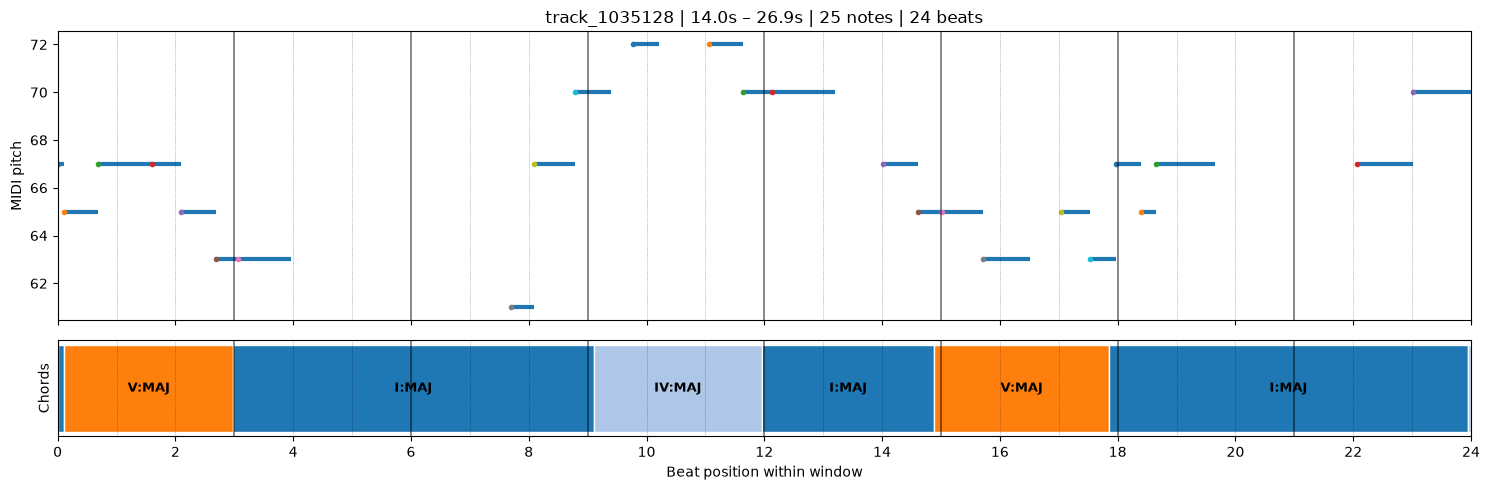

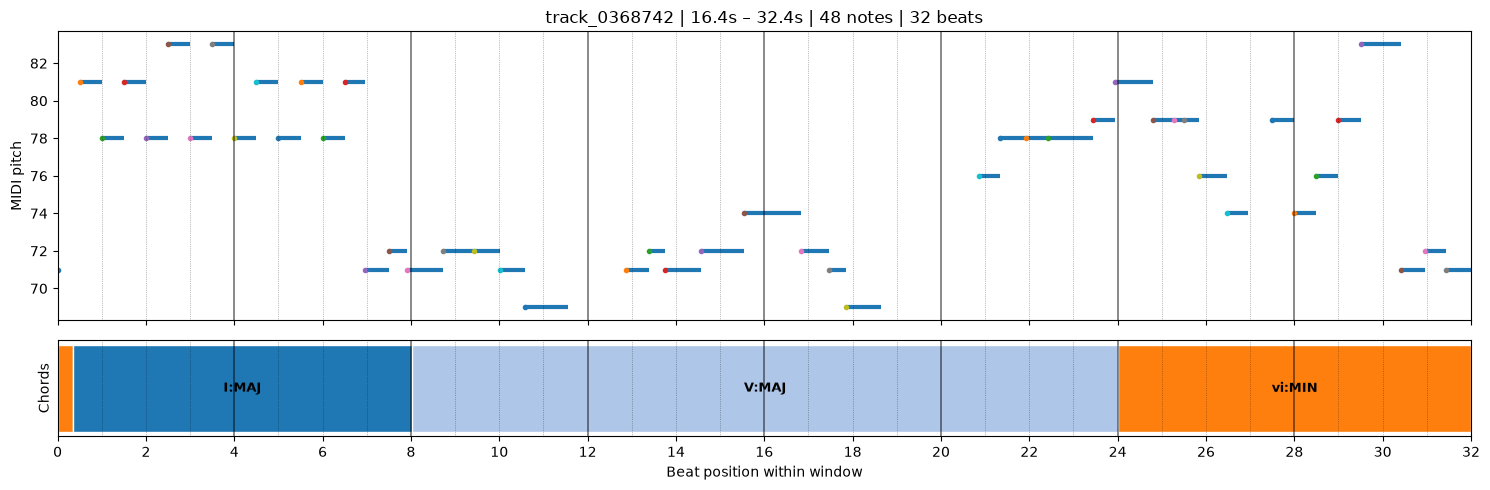

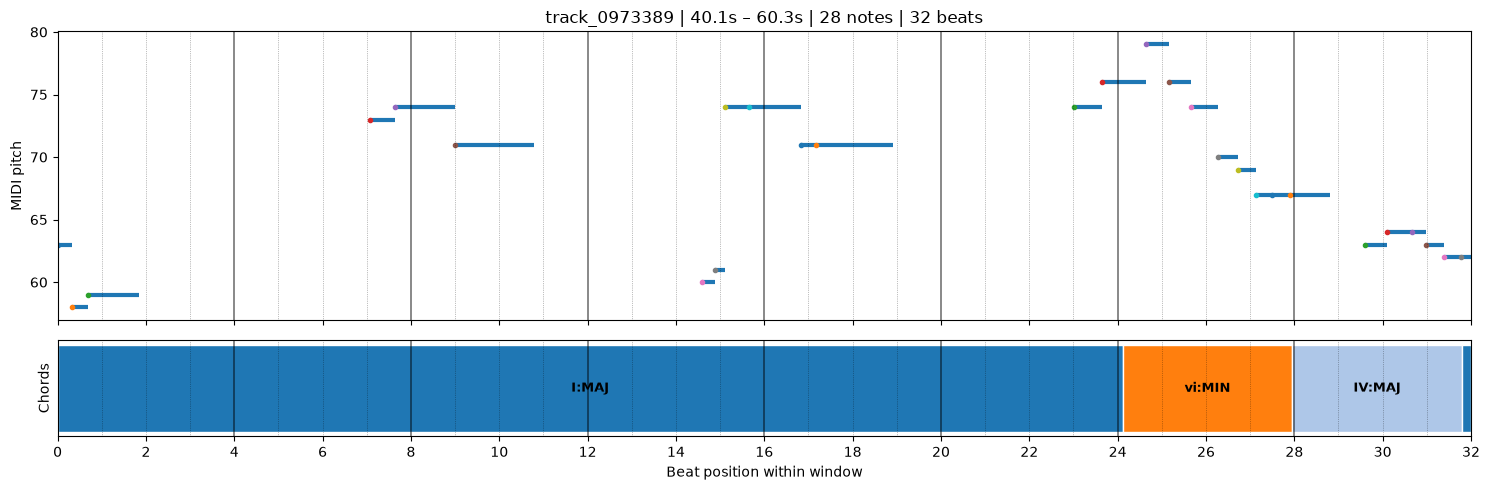

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Select 3 random windows from different training songs
examples = (
    dataset_df[dataset_df["split_0"] == "train"]
    .groupby("track_id", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=3, random_state=10)
)

for row in examples.itertuples():

    start, end = row.start_sec, row.end_sec
    folder = TRACKS_DIR / row.track_id

    notes = load_json(folder / "melody/combined.json")["notes"]
    beats = load_json(folder / "beats/beats.json")["beats"]
    chords = load_json(folder / "roman/submission.json")["events"]

    # Get beats inside this window
    wb = [b for b in beats if start <= b["time_sec"] < end]

    times = np.array([b["time_sec"] for b in wb] + [end])
    positions = np.arange(len(times))

    def to_beat(t):
        return float(np.interp(t, times, positions))

    # Get notes and chords overlapping the window
    wn = [n for n in notes
          if n["onset_sec"] < end and n["offset_sec"] > start]

    wc = [c for c in chords
          if c["start_sec"] < end and c["end_sec"] > start]

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 5),
        sharex=True,
        gridspec_kw={"height_ratios": [3, 1]}
    )

    # -----------------------------------
    # Melody notes (top)
    # -----------------------------------

    for note in wn:

        x1 = to_beat(max(note["onset_sec"], start))
        x2 = to_beat(min(note["offset_sec"], end))
        pitch = note["midi_pitch_rounded"]

        ax1.hlines(pitch, x1, x2, linewidth=3)
        ax1.plot(x1, pitch, marker="o", markersize=3)

    ax1.set_ylabel("MIDI pitch")
    ax1.set_title(
        f"{row.track_id} | {start:.1f}s – {end:.1f}s"
        f" | {len(wn)} notes | {len(wb)} beats"
    )

    # -----------------------------------
    # Chord progression (bottom)
    # -----------------------------------

    labels = sorted(set(c.get("basic_label") or "N" for c in wc))
    cmap = plt.get_cmap("tab20")
    colors = {label: cmap(i % 20) for i, label in enumerate(labels)}

    for chord in wc:

        x1 = to_beat(max(chord["start_sec"], start))
        x2 = to_beat(min(chord["end_sec"], end))

        label = chord.get("basic_label") or "N"

        ax2.barh(
            0, x2 - x1, left=x1,
            height=0.7,
            color=colors[label],
            edgecolor="white"
        )

        if x2 - x1 >= 0.8:
            ax2.text(
                (x1 + x2) / 2, 0,
                label,
                ha="center", va="center",
                fontsize=9,
                fontweight="bold"
            )

    # -----------------------------------
    # Beat and bar boundaries
    # -----------------------------------

    for i, beat in enumerate(wb):

        is_downbeat = beat["beat_in_bar"] == 1

        for ax in (ax1, ax2):
            ax.axvline(
                i,
                color="black",
                linestyle="-" if is_downbeat else ":",
                linewidth=1.3 if is_downbeat else 0.5,
                alpha=0.5
            )

    ax2.set_yticks([])
    ax2.set_ylabel("Chords")
    ax2.set_xlabel("Beat position within window")

    ax1.set_xlim(0, len(wb))
    ax2.set_xticks(range(0, len(wb) + 1, 2))

    plt.tight_layout()
    plt.show()

### Build the PyTorch Dataset

In [11]:
from functools import lru_cache
from torch.utils.data import Dataset


# -----------------------------------
# 1. Cache extracted song data
# -----------------------------------

@lru_cache(maxsize=32)
def load_track_events(track_id):

    folder = TRACKS_DIR / track_id

    notes = load_json(
        folder / "melody" / "combined.json"
    )["notes"]

    beats = load_json(
        folder / "beats" / "beats.json"
    )["beats"]

    chords = load_json(
        folder / "roman" / "submission.json"
    )["events"]

    return notes, beats, chords


# -----------------------------------
# 2. PyTorch Dataset
# -----------------------------------

class MelodyChordDataset(Dataset):

    def __init__(self, dataframe, split):

        assert split in [
            "train", "validation", "test"
        ]

        self.split = split

        self.windows = (
            dataframe[dataframe["split_0"] == split]
            .reset_index(drop=True)
            .to_dict("records")
        )

    def __len__(self):

        return len(self.windows)

    def __getitem__(self, index):

        window = self.windows[index]

        track_id = window["track_id"]
        start = float(window["start_sec"])
        end = float(window["end_sec"])

        tonic_pc = int(window["melody_tonic_pc"])
        mode = window["melody_mode"]

        notes, beats, chords = load_track_events(
            track_id
        )

        # -----------------------------------
        # A. Extract window events
        # -----------------------------------

        wn = sorted(
            [
                n for n in notes
                if n["onset_sec"] < end
                and n["offset_sec"] > start
            ],
            key=lambda n: n["onset_sec"]
        )

        wb = [
            b for b in beats
            if start <= b["time_sec"] < end
        ]

        wc = [
            c for c in chords
            if c["start_sec"] < end
            and c["end_sec"] > start
        ]

        # -----------------------------------
        # B. Beat timeline
        # -----------------------------------

        beat_times = np.array(
            [b["time_sec"] for b in wb] + [end],
            dtype=np.float64
        )

        assert len(wb) > 0
        assert np.all(np.diff(beat_times) > 0)

        beat_positions = np.arange(
            len(beat_times),
            dtype=np.float64
        )

        def to_beat(t):
            return float(
                np.interp(
                    t,
                    beat_times,
                    beat_positions
                )
            )

        # -----------------------------------
        # C. Melody features
        # -----------------------------------

        pitches = []
        onsets = []
        durations = []

        for note in wn:

            note_start = max(
                float(note["onset_sec"]), start
            )

            note_end = min(
                float(note["offset_sec"]), end
            )

            if note_end <= note_start:
                continue

            pitches.append(
                int(note["midi_pitch_rounded"])
            )

            onset_beat = to_beat(note_start)
            offset_beat = to_beat(note_end)

            onsets.append(onset_beat)

            durations.append(
                offset_beat - onset_beat
            )

        assert len(pitches) > 0

        # Key and register normalization
        normalized = normalize_melody_pitches(
            pitches,
            tonic_pc,
            mode
        )

        note_pitch_classes = torch.tensor(
            normalized["relative_pc"].to_numpy(
                dtype=np.int64
            ),
            dtype=torch.long
        )

        note_features = torch.tensor(
            np.column_stack([
                normalized["relative_octave"].to_numpy(),
                onsets,
                durations
            ]),
            dtype=torch.float32
        )

        # -----------------------------------
        # D. Beat features
        # -----------------------------------

        # Two features:
        # 1. Beat position in window (0-based)
        # 2. Beat position in bar (1-based)

        beat_features = torch.tensor(
            [
                [i, b["beat_in_bar"]]
                for i, b in enumerate(wb)
            ],
            dtype=torch.float32
        )

        # -----------------------------------
        # E. Chord targets
        # -----------------------------------

        loss_targets = []
        eval_targets = []

        for i in range(len(wb)):

            beat_start = beat_times[i]
            beat_end = beat_times[i + 1]

            beat_duration = beat_end - beat_start

            overlaps = {}

            for chord in wc:

                label = chord.get("basic_label")

                if (
                    chord.get("mapping_status") != "mapped"
                    or label is None
                    or label == "N"
                ):
                    continue

                overlap = max(
                    0.0,
                    min(beat_end, chord["end_sec"])
                    - max(beat_start, chord["start_sec"])
                )

                if overlap > 0:
                    overlaps[label] = (
                        overlaps.get(label, 0.0)
                        + overlap
                    )

            # Find dominant chord
            if overlaps:

                best_label = max(
                    overlaps,
                    key=overlaps.get
                )

                fraction = (
                    overlaps[best_label]
                    / beat_duration
                )

            else:

                best_label = None
                fraction = 0.0

            # Convert to target IDs
            if (
                best_label is not None
                and fraction >= MIN_CHORD_OVERLAP
            ):

                target_id = encode_chord_label(
                    best_label
                )

                # Preserve unseen labels for evaluation
                eval_targets.append(target_id)

                # CrossEntropyLoss cannot accept -1
                loss_targets.append(
                    target_id
                    if target_id >= 0
                    else IGNORE_INDEX
                )

            else:

                loss_targets.append(IGNORE_INDEX)
                eval_targets.append(IGNORE_INDEX)

        # -----------------------------------
        # F. Musical mode
        # -----------------------------------

        assert mode in ["major", "minor"]

        mode_id = torch.tensor(
            0 if mode == "major" else 1,
            dtype=torch.long
        )

        # -----------------------------------
        # G. Return training example
        # -----------------------------------

        return {
            "track_id": track_id,

            "note_pitch_classes": note_pitch_classes,

            "note_features": note_features,

            "beat_features": beat_features,

            "mode": mode_id,

            "chord_targets": torch.tensor(
                loss_targets,
                dtype=torch.long
            ),

            "eval_targets": torch.tensor(
                eval_targets,
                dtype=torch.long
            )
        }


# -----------------------------------
# 3. Create datasets
# -----------------------------------

train_dataset = MelodyChordDataset(
    dataset_df, "train"
)

val_dataset = MelodyChordDataset(
    dataset_df, "validation"
)

test_dataset = MelodyChordDataset(
    dataset_df, "test"
)


# -----------------------------------
# 4. Display dataset sizes
# -----------------------------------

print("PYTORCH DATASETS")
print("--------------------------------")

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


# -----------------------------------
# 5. Inspect three training examples
# -----------------------------------

print("\nSAMPLE TRAINING WINDOWS")
print("--------------------------------")

sample_indices = [
    0,
    len(train_dataset) // 2,
    len(train_dataset) - 1
]

for index in sample_indices:

    example = train_dataset[index]

    num_notes = len(
        example["note_pitch_classes"]
    )

    num_beats = len(
        example["chord_targets"]
    )

    valid = (
        example["chord_targets"] >= 0
    ).sum().item()

    print(
        f"\nTrack: {example['track_id']}"
    )

    print("Notes:", num_notes)
    print("Beats:", num_beats)
    print("Valid targets:", valid)

    print(
        "Note features:",
        tuple(example["note_features"].shape)
    )

    print(
        "Beat features:",
        tuple(example["beat_features"].shape)
    )

    assert (
        example["note_features"].shape
        == (num_notes, 3)
    )

    assert (
        example["beat_features"].shape
        == (num_beats, 2)
    )

    assert (
        example["chord_targets"].shape
        == (num_beats,)
    )

    assert torch.isfinite(
        example["note_features"]
    ).all()

    assert torch.isfinite(
        example["beat_features"]
    ).all()


print("\nDataset validation passed!")

PYTORCH DATASETS
--------------------------------
Training: 2853
Validation: 1079
Test: 1425

SAMPLE TRAINING WINDOWS
--------------------------------

Track: track_0000390
Notes: 18
Beats: 24
Valid targets: 22
Note features: (18, 3)
Beat features: (24, 2)

Track: track_1061367
Notes: 53
Beats: 32
Valid targets: 28
Note features: (53, 3)
Beat features: (32, 2)

Track: track_1414832
Notes: 45
Beats: 32
Valid targets: 32
Note features: (45, 3)
Beat features: (32, 2)

Dataset validation passed!


### Create DataLoaders

In [12]:
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence


# -----------------------------------
# 1. Configuration
# -----------------------------------

BATCH_SIZE = 16

# Valid pitch classes: 0–11
# Reserved value for padding: 12
NOTE_PAD_ID = 12


# -----------------------------------
# 2. Custom batch collator
# -----------------------------------

def collate_melody_chord(batch):

    # Original sequence lengths
    note_lengths = torch.tensor(
        [
            len(item["note_pitch_classes"])
            for item in batch
        ],
        dtype=torch.long
    )

    beat_lengths = torch.tensor(
        [
            len(item["beat_features"])
            for item in batch
        ],
        dtype=torch.long
    )

    # -----------------------------------
    # A. Pad melody pitch classes
    # -----------------------------------

    note_pitch_classes = pad_sequence(
        [
            item["note_pitch_classes"]
            for item in batch
        ],
        batch_first=True,
        padding_value=NOTE_PAD_ID
    )

    # -----------------------------------
    # B. Pad melody numerical features
    # -----------------------------------

    note_features = pad_sequence(
        [
            item["note_features"]
            for item in batch
        ],
        batch_first=True,
        padding_value=0.0
    )

    # -----------------------------------
    # C. Pad beat features
    # -----------------------------------

    beat_features = pad_sequence(
        [
            item["beat_features"]
            for item in batch
        ],
        batch_first=True,
        padding_value=0.0
    )

    # -----------------------------------
    # D. Pad chord targets
    # -----------------------------------

    chord_targets = pad_sequence(
        [
            item["chord_targets"]
            for item in batch
        ],
        batch_first=True,
        padding_value=IGNORE_INDEX
    )

    eval_targets = pad_sequence(
        [
            item["eval_targets"]
            for item in batch
        ],
        batch_first=True,
        padding_value=IGNORE_INDEX
    )

    # -----------------------------------
    # E. Stack musical modes
    # -----------------------------------

    modes = torch.stack([
        item["mode"]
        for item in batch
    ])

    # -----------------------------------
    # F. Create padding masks
    # -----------------------------------

    # True = padding position
    # False = real position

    max_notes = note_pitch_classes.shape[1]
    max_beats = beat_features.shape[1]

    note_padding_mask = (
        torch.arange(max_notes)[None, :]
        >= note_lengths[:, None]
    )

    beat_padding_mask = (
        torch.arange(max_beats)[None, :]
        >= beat_lengths[:, None]
    )

    # -----------------------------------
    # G. Return batch
    # -----------------------------------

    return {
        "track_ids": [
            item["track_id"]
            for item in batch
        ],

        "note_pitch_classes": note_pitch_classes,
        "note_features": note_features,

        "beat_features": beat_features,

        "mode": modes,

        "chord_targets": chord_targets,
        "eval_targets": eval_targets,

        "note_padding_mask": note_padding_mask,
        "beat_padding_mask": beat_padding_mask,

        "note_lengths": note_lengths,
        "beat_lengths": beat_lengths
    }


# -----------------------------------
# 3. Create DataLoaders
# -----------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_melody_chord,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_melody_chord,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_melody_chord,
    num_workers=0
)


# -----------------------------------
# 4. Inspect one training batch
# -----------------------------------

batch = next(iter(train_loader))

print("FIRST TRAINING BATCH")
print("--------------------------------")

for name, value in batch.items():

    if isinstance(value, torch.Tensor):
        print(
            f"{name:23s} "
            f"{tuple(value.shape)}"
        )


# -----------------------------------
# 5. Inspect padding
# -----------------------------------

print("\nSEQUENCE LENGTHS")
print("--------------------------------")

print(
    "Note lengths:",
    batch["note_lengths"].tolist()
)

print(
    "Beat lengths:",
    batch["beat_lengths"].tolist()
)

print(
    "\nMaximum notes:",
    batch["note_pitch_classes"].shape[1]
)

print(
    "Maximum beats:",
    batch["beat_features"].shape[1]
)


# -----------------------------------
# 6. Validate padding
# -----------------------------------

assert torch.equal(
    batch["note_padding_mask"],
    batch["note_pitch_classes"] == NOTE_PAD_ID
)

assert (
    batch["chord_targets"][
        batch["beat_padding_mask"]
    ] == IGNORE_INDEX
).all()

assert (
    batch["note_lengths"] > 0
).all()

assert (
    batch["beat_lengths"] > 0
).all()

assert torch.isfinite(
    batch["note_features"]
).all()

assert torch.isfinite(
    batch["beat_features"]
).all()


print("\nBATCH VALIDATION")
print("--------------------------------")

print(
    "Real melody notes:",
    (~batch["note_padding_mask"]).sum().item()
)

print(
    "Padded note positions:",
    batch["note_padding_mask"].sum().item()
)

print(
    "Valid chord targets:",
    (batch["chord_targets"] >= 0).sum().item()
)

print(
    "Masked chord targets:",
    (
        (batch["chord_targets"] == IGNORE_INDEX)
        & ~batch["beat_padding_mask"]
    ).sum().item()
)

print("\nDataLoader validation passed!")

FIRST TRAINING BATCH
--------------------------------
note_pitch_classes      (16, 95)
note_features           (16, 95, 3)
beat_features           (16, 48, 2)
mode                    (16,)
chord_targets           (16, 48)
eval_targets            (16, 48)
note_padding_mask       (16, 95)
beat_padding_mask       (16, 48)
note_lengths            (16,)
beat_lengths            (16,)

SEQUENCE LENGTHS
--------------------------------
Note lengths: [48, 11, 48, 64, 95, 24, 30, 38, 25, 28, 31, 74, 44, 49, 57, 15]
Beat lengths: [32, 32, 32, 32, 32, 16, 32, 16, 16, 24, 48, 32, 32, 32, 32, 16]

Maximum notes: 95
Maximum beats: 48

BATCH VALIDATION
--------------------------------
Real melody notes: 681
Padded note positions: 839
Valid chord targets: 413
Masked chord targets: 43

DataLoader validation passed!


## Building the Transformer

### Note Embedding Layer

In [13]:
import torch
import torch.nn as nn


# -----------------------------------
# 1. Model configuration
# -----------------------------------

D_MODEL = 128
DROPOUT = 0.1


# -----------------------------------
# 2. Note embedding module
# -----------------------------------

class NoteEmbedding(nn.Module):

    def __init__(self, d_model=128, dropout=0.1):

        super().__init__()

        # A. Relative pitch-class embedding
        # 12 real pitch classes + 1 padding ID

        self.pitch_embedding = nn.Embedding(
            num_embeddings=13,
            embedding_dim=d_model,
            padding_idx=NOTE_PAD_ID
        )

        # B. Numerical feature projection
        # Input: octave, onset, duration

        self.numeric_projection = nn.Sequential(
            nn.Linear(3, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model)
        )

        # C. Major/minor mode embedding

        self.mode_embedding = nn.Embedding(
            num_embeddings=2,
            embedding_dim=d_model
        )

        # D. Normalization and dropout

        self.layer_norm = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)


    def forward(
        self,
        note_pitch_classes,
        note_features,
        modes,
        beat_lengths,
        note_padding_mask
    ):

        # -----------------------------------
        # A. Embed pitch classes
        # -----------------------------------

        pitch_emb = self.pitch_embedding(
            note_pitch_classes
        )

        # -----------------------------------
        # B. Normalize numerical features
        # -----------------------------------

        octave = (
            note_features[:, :, 0:1] / 2.0
        )

        onset = (
            note_features[:, :, 1:2]
            / beat_lengths[:, None, None].clamp(min=1)
        )

        duration = torch.log1p(
            note_features[:, :, 2:3].clamp(min=0)
        )

        numerical_input = torch.cat(
            [octave, onset, duration],
            dim=-1
        )

        numeric_emb = self.numeric_projection(
            numerical_input
        )

        # -----------------------------------
        # C. Embed musical mode
        # -----------------------------------

        mode_emb = self.mode_embedding(
            modes
        ).unsqueeze(1)

        # -----------------------------------
        # D. Combine embeddings
        # -----------------------------------

        x = (
            pitch_emb
            + numeric_emb
            + mode_emb
        )

        x = self.layer_norm(x)

        x = self.dropout(x)

        # -----------------------------------
        # E. Zero out padding positions
        # -----------------------------------

        x = x.masked_fill(
            note_padding_mask.unsqueeze(-1),
            0.0
        )

        return x


# -----------------------------------
# 3. Initialize embedding module
# -----------------------------------

note_embedding = NoteEmbedding(
    d_model=D_MODEL,
    dropout=DROPOUT
)

note_embedding.eval()


# -----------------------------------
# 4. Test using our existing batch
# -----------------------------------

with torch.no_grad():

    embedded_notes = note_embedding(
        note_pitch_classes=batch["note_pitch_classes"],
        note_features=batch["note_features"],
        modes=batch["mode"],
        beat_lengths=batch["beat_lengths"],
        note_padding_mask=batch["note_padding_mask"]
    )


# -----------------------------------
# 5. Display results
# -----------------------------------

print("NOTE EMBEDDING LAYER")
print("--------------------------------")

print(
    "Input pitch shape:",
    tuple(batch["note_pitch_classes"].shape)
)

print(
    "Input numerical shape:",
    tuple(batch["note_features"].shape)
)

print(
    "Output embedding shape:",
    tuple(embedded_notes.shape)
)

print(
    "\nEmbedding dimension:",
    D_MODEL
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in note_embedding.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 6. Validate embeddings
# -----------------------------------

assert embedded_notes.shape == (
    BATCH_SIZE,
    batch["note_pitch_classes"].shape[1],
    D_MODEL
)

assert torch.isfinite(
    embedded_notes
).all()

# Padding embeddings must be zero
assert (
    embedded_notes[
        batch["note_padding_mask"]
    ] == 0
).all()

# Real notes must contain nonzero embeddings
assert (
    embedded_notes[
        ~batch["note_padding_mask"]
    ].abs().sum(dim=-1) > 0
).all()


print("\nEmbedding validation passed!")

NOTE EMBEDDING LAYER
--------------------------------
Input pitch shape: (16, 95)
Input numerical shape: (16, 95, 3)
Output embedding shape: (16, 95, 128)

Embedding dimension: 128
Trainable parameters: 19200

Embedding validation passed!


### Implement the Melody Encoder

In [14]:
import torch
import torch.nn as nn


# -----------------------------------
# 1. Transformer configuration
# -----------------------------------

NUM_ENCODER_LAYERS = 2
NUM_ATTENTION_HEADS = 4
DIM_FEEDFORWARD = 256


# -----------------------------------
# 2. Melody Transformer Encoder
# -----------------------------------

class MelodyEncoder(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_layers=2,
        num_heads=4,
        dim_feedforward=256,
        dropout=0.1
    ):

        super().__init__()

        # Create independently initialized
        # Transformer encoder layers

        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=num_heads,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True
            )
            for _ in range(num_layers)
        ])

        self.final_norm = nn.LayerNorm(d_model)


    def forward(
        self,
        note_embeddings,
        note_padding_mask
    ):

        x = note_embeddings

        # -----------------------------------
        # Apply Transformer layers
        # -----------------------------------

        for layer in self.layers:

            x = layer(
                x,
                src_key_padding_mask=note_padding_mask
            )

        # -----------------------------------
        # Final normalization
        # -----------------------------------

        x = self.final_norm(x)

        # Zero out padded note positions
        x = x.masked_fill(
            note_padding_mask.unsqueeze(-1),
            0.0
        )

        return x


# -----------------------------------
# 3. Initialize encoder
# -----------------------------------

melody_encoder = MelodyEncoder(
    d_model=D_MODEL,
    num_layers=NUM_ENCODER_LAYERS,
    num_heads=NUM_ATTENTION_HEADS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

melody_encoder.eval()


# -----------------------------------
# 4. Process our note embeddings
# -----------------------------------

with torch.no_grad():

    contextual_notes = melody_encoder(
        note_embeddings=embedded_notes,
        note_padding_mask=batch["note_padding_mask"]
    )


# -----------------------------------
# 5. Display results
# -----------------------------------

print("MELODY TRANSFORMER ENCODER")
print("--------------------------------")

print(
    "Input shape:",
    tuple(embedded_notes.shape)
)

print(
    "Output shape:",
    tuple(contextual_notes.shape)
)

print(
    "Transformer layers:",
    NUM_ENCODER_LAYERS
)

print(
    "Attention heads:",
    NUM_ATTENTION_HEADS
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in melody_encoder.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 6. Validate encoder
# -----------------------------------

assert contextual_notes.shape == (
    embedded_notes.shape
)

assert torch.isfinite(
    contextual_notes
).all()

# Padded positions must remain zero
assert (
    contextual_notes[
        batch["note_padding_mask"]
    ] == 0
).all()

# Real positions should contain information
assert (
    contextual_notes[
        ~batch["note_padding_mask"]
    ].abs().sum(dim=-1) > 0
).all()


# -----------------------------------
# 7. Compare embeddings
# -----------------------------------

difference = (
    contextual_notes - embedded_notes
).abs()

real_difference = difference[
    ~batch["note_padding_mask"]
].mean().item()

print("\nEMBEDDING COMPARISON")
print("--------------------------------")

print(
    "Mean absolute difference:",
    round(real_difference, 4)
)

print("\nTransformer encoder validation passed!")

MELODY TRANSFORMER ENCODER
--------------------------------
Input shape: (16, 95, 128)
Output shape: (16, 95, 128)
Transformer layers: 2
Attention heads: 4
Trainable parameters: 265216

EMBEDDING COMPARISON
--------------------------------
Mean absolute difference: 0.3668

Transformer encoder validation passed!


### Beat-Query Cross-Attention

In [15]:
import torch
import torch.nn as nn


# -----------------------------------
# 1. Beat-Query Cross-Attention
# -----------------------------------

class BeatQueryCrossAttention(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        dropout=0.1
    ):

        super().__init__()

        # A. Convert beat features into embeddings
        self.beat_projection = nn.Sequential(
            nn.Linear(2, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model)
        )

        # B. Musical mode embedding
        self.mode_embedding = nn.Embedding(
            2, d_model
        )

        # C. Cross-attention
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        # D. Normalization
        self.layer_norm = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)


    def forward(
        self,
        contextual_notes,
        beat_features,
        modes,
        beat_lengths,
        note_padding_mask,
        beat_padding_mask
    ):

        # -----------------------------------
        # A. Normalize beat positions
        # -----------------------------------

        # Beat index inside the window
        beat_index = beat_features[:, :, 0:1]

        # Position inside the musical bar
        beat_in_bar = beat_features[:, :, 1:2]

        # Normalize beat position by window length
        beat_position = (
            beat_index
            / beat_lengths[:, None, None].clamp(min=1)
        )

        # Estimate beats per bar from actual positions
        beats_per_bar = (
            beat_in_bar.amax(dim=1, keepdim=True)
            .clamp(min=1)
        )

        # Normalize position within the bar
        bar_position = (
            (beat_in_bar - 1).clamp(min=0)
            / beats_per_bar
        )

        # Combine position features
        normalized_beat_features = torch.cat(
            [
                beat_position,
                bar_position
            ],
            dim=-1
        )


        # -----------------------------------
        # B. Create beat queries
        # -----------------------------------

        beat_queries = self.beat_projection(
            normalized_beat_features
        )

        mode_emb = self.mode_embedding(
            modes
        ).unsqueeze(1)

        beat_queries = beat_queries + mode_emb


        # -----------------------------------
        # C. Cross-attention
        # -----------------------------------

        attended_notes, attention_weights = (
            self.cross_attention(
                query=beat_queries,
                key=contextual_notes,
                value=contextual_notes,
                key_padding_mask=note_padding_mask,
                need_weights=True
            )
        )


        # -----------------------------------
        # D. Residual connection + normalization
        # -----------------------------------

        beat_representations = self.layer_norm(
            beat_queries
            + self.dropout(attended_notes)
        )


        # -----------------------------------
        # E. Mask padded beat positions
        # -----------------------------------

        beat_representations = (
            beat_representations.masked_fill(
                beat_padding_mask.unsqueeze(-1),
                0.0
            )
        )

        return beat_representations, attention_weights


# -----------------------------------
# 2. Initialize module
# -----------------------------------

beat_attention = BeatQueryCrossAttention(
    d_model=D_MODEL,
    num_heads=NUM_ATTENTION_HEADS,
    dropout=DROPOUT
)

beat_attention.eval()


# -----------------------------------
# 3. Test with existing batch
# -----------------------------------

with torch.no_grad():

    beat_representations, attention_weights = (
        beat_attention(
            contextual_notes=contextual_notes,
            beat_features=batch["beat_features"],
            modes=batch["mode"],
            beat_lengths=batch["beat_lengths"],
            note_padding_mask=batch["note_padding_mask"],
            beat_padding_mask=batch["beat_padding_mask"]
        )
    )


# -----------------------------------
# 4. Display results
# -----------------------------------

print("BEAT-QUERY CROSS-ATTENTION")
print("--------------------------------")

print(
    "Input note representations:",
    tuple(contextual_notes.shape)
)

print(
    "Input beat features:",
    tuple(batch["beat_features"].shape)
)

print(
    "Output beat representations:",
    tuple(beat_representations.shape)
)

print(
    "Attention weights:",
    tuple(attention_weights.shape)
)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in beat_attention.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 5. Validate output dimensions
# -----------------------------------

batch_size = len(batch["mode"])

max_beats = batch["beat_features"].shape[1]

max_notes = contextual_notes.shape[1]

assert beat_representations.shape == (
    batch_size,
    max_beats,
    D_MODEL
)

assert attention_weights.shape == (
    batch_size,
    max_beats,
    max_notes
)


# -----------------------------------
# 6. Validate numerical values
# -----------------------------------

assert torch.isfinite(
    beat_representations
).all()

assert torch.isfinite(
    attention_weights
).all()


# -----------------------------------
# 7. Verify padding masks
# -----------------------------------

# Padded beat outputs must be zero
assert (
    beat_representations[
        batch["beat_padding_mask"]
    ] == 0
).all()

# Real beat representations must be nonzero
assert (
    beat_representations[
        ~batch["beat_padding_mask"]
    ].abs().sum(dim=-1) > 0
).all()

# Padded notes must receive zero attention
padded_note_attention = attention_weights.masked_select(
    batch["note_padding_mask"][:, None, :]
    .expand_as(attention_weights)
)

assert (
    padded_note_attention.abs() < 1e-6
).all()

# Attention over real notes should sum to 1
real_beat_attention_sums = (
    attention_weights.sum(dim=-1)[
        ~batch["beat_padding_mask"]
    ]
)

assert torch.allclose(
    real_beat_attention_sums,
    torch.ones_like(real_beat_attention_sums),
    atol=1e-5
)


print("\nCross-attention validation passed!")

BEAT-QUERY CROSS-ATTENTION
--------------------------------
Input note representations: (16, 95, 128)
Input beat features: (16, 48, 2)
Output beat representations: (16, 48, 128)
Attention weights: (16, 48, 95)

Trainable parameters: 83456

Cross-attention validation passed!


### Beat Sequence Transformer

In [16]:
# -----------------------------------
# 1. Configuration
# -----------------------------------

NUM_BEAT_LAYERS = 2


# -----------------------------------
# 2. Beat Sequence Transformer
# -----------------------------------

class BeatSequenceEncoder(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_layers=2,
        num_heads=4,
        dim_feedforward=256,
        dropout=0.1
    ):

        super().__init__()

        # Transformer encoder layers
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=num_heads,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True
            )
            for _ in range(num_layers)
        ])

        self.final_norm = nn.LayerNorm(
            d_model
        )

    def forward(
        self,
        beat_representations,
        beat_padding_mask
    ):

        x = beat_representations

        # -----------------------------------
        # A. Beat-to-beat self-attention
        # -----------------------------------

        for layer in self.layers:

            x = layer(
                x,
                src_key_padding_mask=beat_padding_mask
            )

        # -----------------------------------
        # B. Final normalization
        # -----------------------------------

        x = self.final_norm(x)

        # -----------------------------------
        # C. Remove padded representations
        # -----------------------------------

        x = x.masked_fill(
            beat_padding_mask.unsqueeze(-1),
            0.0
        )

        return x


# -----------------------------------
# 3. Initialize module
# -----------------------------------

beat_encoder = BeatSequenceEncoder(
    d_model=D_MODEL,
    num_layers=NUM_BEAT_LAYERS,
    num_heads=NUM_ATTENTION_HEADS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

beat_encoder.eval()


# -----------------------------------
# 4. Process beat representations
# -----------------------------------

with torch.no_grad():

    contextual_beats = beat_encoder(
        beat_representations=beat_representations,
        beat_padding_mask=batch["beat_padding_mask"]
    )


# -----------------------------------
# 5. Display results
# -----------------------------------

print("BEAT SEQUENCE TRANSFORMER")
print("--------------------------------")

print(
    "Input shape:",
    tuple(beat_representations.shape)
)

print(
    "Output shape:",
    tuple(contextual_beats.shape)
)

print(
    "Transformer layers:",
    NUM_BEAT_LAYERS
)

print(
    "Attention heads:",
    NUM_ATTENTION_HEADS
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in beat_encoder.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 6. Validate dimensions
# -----------------------------------

assert (
    contextual_beats.shape
    == beat_representations.shape
)

assert torch.isfinite(
    contextual_beats
).all()


# -----------------------------------
# 7. Validate padding
# -----------------------------------

assert (
    contextual_beats[
        batch["beat_padding_mask"]
    ] == 0
).all()

assert (
    contextual_beats[
        ~batch["beat_padding_mask"]
    ].abs().sum(dim=-1) > 0
).all()


# -----------------------------------
# 8. Compare representations
# -----------------------------------

difference = (
    contextual_beats - beat_representations
).abs()

real_difference = difference[
    ~batch["beat_padding_mask"]
].mean().item()

print("\nREPRESENTATION COMPARISON")
print("--------------------------------")

print(
    "Mean absolute difference:",
    round(real_difference, 4)
)


# -----------------------------------
# 9. Verify padded beats cannot
#    influence real beat outputs
# -----------------------------------

modified_input = beat_representations.clone()

modified_input[
    batch["beat_padding_mask"]
] = 100.0

with torch.no_grad():

    modified_output = beat_encoder(
        modified_input,
        batch["beat_padding_mask"]
    )

assert torch.allclose(
    contextual_beats[
        ~batch["beat_padding_mask"]
    ],
    modified_output[
        ~batch["beat_padding_mask"]
    ],
    atol=1e-5,
    rtol=1e-5
)

print("\nPadding isolation: PASSED")
print("Beat Transformer validation passed!")

BEAT SEQUENCE TRANSFORMER
--------------------------------
Input shape: (16, 48, 128)
Output shape: (16, 48, 128)
Transformer layers: 2
Attention heads: 4
Trainable parameters: 265216

REPRESENTATION COMPARISON
--------------------------------
Mean absolute difference: 0.4806

Padding isolation: PASSED
Beat Transformer validation passed!


### Chord Prediction Head

In [17]:
# -----------------------------------
# 1. Chord Prediction Head
# -----------------------------------

class ChordPredictionHead(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_chord_classes=59
    ):

        super().__init__()

        # Convert each 128-dimensional beat
        # representation into 59 chord scores

        self.classifier = nn.Linear(
            d_model,
            num_chord_classes
        )

    def forward(
        self,
        contextual_beats,
        beat_padding_mask
    ):

        # -----------------------------------
        # A. Predict chord logits
        # -----------------------------------

        logits = self.classifier(
            contextual_beats
        )

        # -----------------------------------
        # B. Mask padded beat positions
        # -----------------------------------

        logits = logits.masked_fill(
            beat_padding_mask.unsqueeze(-1),
            0.0
        )

        return logits


# -----------------------------------
# 2. Initialize prediction head
# -----------------------------------

chord_head = ChordPredictionHead(
    d_model=D_MODEL,
    num_chord_classes=NUM_CHORD_CLASSES
)

chord_head.eval()


# -----------------------------------
# 3. Predict chords for our batch
# -----------------------------------

with torch.no_grad():

    chord_logits = chord_head(
        contextual_beats=contextual_beats,
        beat_padding_mask=batch["beat_padding_mask"]
    )

    # Convert logits into probabilities
    chord_probabilities = torch.softmax(
        chord_logits,
        dim=-1
    )

    # Select most probable chord class
    predicted_chords = torch.argmax(
        chord_probabilities,
        dim=-1
    )


# -----------------------------------
# 4. Display results
# -----------------------------------

print("CHORD PREDICTION HEAD")
print("--------------------------------")

print(
    "Input shape:",
    tuple(contextual_beats.shape)
)

print(
    "Output logits:",
    tuple(chord_logits.shape)
)

print(
    "Predicted chord IDs:",
    tuple(predicted_chords.shape)
)

print(
    "\nChord classes:",
    NUM_CHORD_CLASSES
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in chord_head.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 5. Validate dimensions
# -----------------------------------

assert chord_logits.shape == (
    len(batch["mode"]),
    batch["beat_features"].shape[1],
    NUM_CHORD_CLASSES
)

assert predicted_chords.shape == (
    batch["chord_targets"].shape
)


# -----------------------------------
# 6. Validate predictions
# -----------------------------------

assert torch.isfinite(
    chord_logits
).all()

assert (
    (predicted_chords >= 0)
    & (predicted_chords < NUM_CHORD_CLASSES)
).all()

# Probabilities must sum to 1
real_beats = ~batch["beat_padding_mask"]

probability_sums = (
    chord_probabilities.sum(dim=-1)
)

assert torch.allclose(
    probability_sums[real_beats],
    torch.ones_like(
        probability_sums[real_beats]
    ),
    atol=1e-5
)

# Padded logits must be zero
assert (
    chord_logits[
        batch["beat_padding_mask"]
    ] == 0
).all()


# -----------------------------------
# 7. Inspect first window
# -----------------------------------

print("\nFIRST WINDOW — PREDICTIONS")
print("--------------------------------")

first_length = batch["beat_lengths"][0].item()

first_predictions = predicted_chords[
    0, :first_length
].tolist()

first_targets = batch["chord_targets"][
    0, :first_length
].tolist()

comparison = pd.DataFrame({
    "beat": range(1, first_length + 1),

    "actual_chord": [
        ID_TO_CHORD.get(t, "MASKED")
        for t in first_targets
    ],

    "predicted_chord": [
        ID_TO_CHORD[p]
        for p in first_predictions
    ]
})

display(comparison.head(16))

print("\nPrediction head validation passed!")
print("Note: Predictions are from an UNTRAINED model.")

CHORD PREDICTION HEAD
--------------------------------
Input shape: (16, 48, 128)
Output logits: (16, 48, 61)
Predicted chord IDs: (16, 48)

Chord classes: 61
Trainable parameters: 7869

FIRST WINDOW — PREDICTIONS
--------------------------------


,beat,actual_chord,predicted_chord
0,1,i:MIN,biii:DIM
1,2,i:MIN,biii:DIM
2,3,i:MIN,biii:DIM
3,4,i:MIN,biii:DIM
4,5,i:MIN,biii:DIM
5,6,i:MIN,biii:DIM
6,7,i:MIN,biii:DIM
7,8,i:MIN,biii:DIM
8,9,i:MIN,biii:DIM
9,10,i:MIN,biii:DIM



Prediction head validation passed!
Note: Predictions are from an UNTRAINED model.


### Complete Melody-to-Chord Transformer

In [19]:
# -----------------------------------
# 1. Complete Transformer model
# -----------------------------------

class MelodyChordTransformer(nn.Module):

    def __init__(
        self,
        d_model=128,
        num_heads=4,
        num_melody_layers=2,
        num_beat_layers=2,
        dim_feedforward=256,
        num_chord_classes=59,
        dropout=0.1
    ):

        super().__init__()

        # -----------------------------------
        # A. Note embedding
        # -----------------------------------

        self.note_embedding = NoteEmbedding(
            d_model=d_model,
            dropout=dropout
        )

        # -----------------------------------
        # B. Melody Transformer encoder
        # -----------------------------------

        self.melody_encoder = MelodyEncoder(
            d_model=d_model,
            num_layers=num_melody_layers,
            num_heads=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )

        # -----------------------------------
        # C. Beat-query cross-attention
        # -----------------------------------

        self.beat_attention = BeatQueryCrossAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        # -----------------------------------
        # D. Beat Transformer encoder
        # -----------------------------------

        self.beat_encoder = BeatSequenceEncoder(
            d_model=d_model,
            num_layers=num_beat_layers,
            num_heads=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )

        # -----------------------------------
        # E. Chord prediction head
        # -----------------------------------

        self.chord_head = ChordPredictionHead(
            d_model=d_model,
            num_chord_classes=num_chord_classes
        )


    def forward(self, batch):

        # -----------------------------------
        # 1. Embed melody notes
        # -----------------------------------

        note_embeddings = self.note_embedding(
            note_pitch_classes=batch["note_pitch_classes"],
            note_features=batch["note_features"],
            modes=batch["mode"],
            beat_lengths=batch["beat_lengths"],
            note_padding_mask=batch["note_padding_mask"]
        )

        # -----------------------------------
        # 2. Encode melody
        # -----------------------------------

        contextual_notes = self.melody_encoder(
            note_embeddings=note_embeddings,
            note_padding_mask=batch["note_padding_mask"]
        )

        # -----------------------------------
        # 3. Melody-to-beat cross-attention
        # -----------------------------------

        beat_representations, attention_weights = (
            self.beat_attention(
                contextual_notes=contextual_notes,
                beat_features=batch["beat_features"],
                modes=batch["mode"],
                beat_lengths=batch["beat_lengths"],
                note_padding_mask=batch["note_padding_mask"],
                beat_padding_mask=batch["beat_padding_mask"]
            )
        )

        # -----------------------------------
        # 4. Encode beat sequence
        # -----------------------------------

        contextual_beats = self.beat_encoder(
            beat_representations=beat_representations,
            beat_padding_mask=batch["beat_padding_mask"]
        )

        # -----------------------------------
        # 5. Predict Roman numeral chords
        # -----------------------------------

        logits = self.chord_head(
            contextual_beats=contextual_beats,
            beat_padding_mask=batch["beat_padding_mask"]
        )

        return {
            "logits": logits,
            "attention_weights": attention_weights
        }


# -----------------------------------
# 2. Initialize complete model
# -----------------------------------

model = MelodyChordTransformer(
    d_model=D_MODEL,
    num_heads=NUM_ATTENTION_HEADS,
    num_melody_layers=NUM_ENCODER_LAYERS,
    num_beat_layers=NUM_BEAT_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    num_chord_classes=NUM_CHORD_CLASSES,
    dropout=DROPOUT
)

model.eval()


# -----------------------------------
# 3. Complete forward pass
# -----------------------------------

with torch.no_grad():

    outputs = model(batch)

    logits = outputs["logits"]

    predictions = logits.argmax(dim=-1)


# -----------------------------------
# 4. Display results
# -----------------------------------

print("COMPLETE MELODY-TO-CHORD TRANSFORMER")
print("--------------------------------")

print(
    "Input melody:",
    tuple(batch["note_pitch_classes"].shape)
)

print(
    "Output chord logits:",
    tuple(logits.shape)
)

print(
    "Attention weights:",
    tuple(outputs["attention_weights"].shape)
)

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)


# -----------------------------------
# 5. Validate complete model
# -----------------------------------

assert logits.shape == (
    len(batch["mode"]),
    batch["beat_features"].shape[1],
    NUM_CHORD_CLASSES
)

assert torch.isfinite(logits).all()

assert (
    logits[batch["beat_padding_mask"]] == 0
).all()

assert (
    sum(p.numel() for p in model.parameters())
    == 640699
)


# -----------------------------------
# 6. Inspect first window
# -----------------------------------

first_length = batch["beat_lengths"][0].item()

actual = batch["chord_targets"][
    0, :first_length
].tolist()

predicted = predictions[
    0, :first_length
].tolist()

comparison_df = pd.DataFrame({
    "beat": range(1, first_length + 1),

    "actual": [
        ID_TO_CHORD.get(label, "MASKED")
        for label in actual
    ],

    "predicted": [
        ID_TO_CHORD[label]
        for label in predicted
    ]
})

print("\nFIRST WINDOW — PREDICTIONS")
print("--------------------------------")

display(comparison_df.head(16))


print("\nComplete forward pass: PASSED")
print("Model status: UNTRAINED")

COMPLETE MELODY-TO-CHORD TRANSFORMER
--------------------------------
Input melody: (16, 95)
Output chord logits: (16, 48, 61)
Attention weights: (16, 48, 95)

Trainable parameters: 640957


AssertionError: 

### Test Loss and Backpropagation

In [20]:
import torch
import torch.nn as nn


# -----------------------------------
# 1. Define loss function
# -----------------------------------

loss_fn = nn.CrossEntropyLoss(
    ignore_index=IGNORE_INDEX
)


# -----------------------------------
# 2. Enable training mode
# -----------------------------------

model.train()

# Clear previous gradients
model.zero_grad(set_to_none=True)


# -----------------------------------
# 3. Forward pass
# -----------------------------------

outputs = model(batch)

logits = outputs["logits"]

targets = batch["chord_targets"]

# Keep gradients for validation
logits.retain_grad()


# -----------------------------------
# 4. Calculate loss
# -----------------------------------

# logits: [batch, beats, classes]
# CrossEntropyLoss expects:
# [batch, classes, beats]

loss = loss_fn(
    logits.transpose(1, 2),
    targets
)

print("TRAINING LOSS")
print("--------------------------------")

print("Initial loss:", round(loss.item(), 4))

assert torch.isfinite(loss)


# -----------------------------------
# 5. Backpropagation
# -----------------------------------

loss.backward()

print("\nBACKPROPAGATION")
print("--------------------------------")

print("Backward pass completed!")


# -----------------------------------
# 6. Check gradients in each component
# -----------------------------------

components = {
    "Note Embedding": model.note_embedding,
    "Melody Encoder": model.melody_encoder,
    "Beat Cross-Attention": model.beat_attention,
    "Beat Encoder": model.beat_encoder,
    "Chord Prediction Head": model.chord_head
}

gradient_results = {}

for name, module in components.items():

    total_gradient = 0.0

    for parameter in module.parameters():

        if parameter.grad is not None:

            assert torch.isfinite(
                parameter.grad
            ).all()

            total_gradient += (
                parameter.grad.norm().item()
            )

    gradient_results[name] = total_gradient

    print(
        f"{name:24s}: "
        f"{total_gradient:.6f}"
    )


# -----------------------------------
# 7. Verify all components receive
#    nonzero gradients
# -----------------------------------

assert all(
    gradient > 0
    for gradient in gradient_results.values()
)


# -----------------------------------
# 8. Check that loss masking works
# -----------------------------------

valid_mask = (
    targets >= 0
)

masked_mask = (
    targets == IGNORE_INDEX
)

print("\nLOSS MASKING")
print("--------------------------------")

print(
    "Valid targets:",
    valid_mask.sum().item()
)

print(
    "Ignored targets:",
    masked_mask.sum().item()
)

# Masked positions must receive
# zero gradients at the logits

assert (
    logits.grad[masked_mask] == 0
).all()

print("Masked gradients: ZERO (correct)")


# -----------------------------------
# 9. Calculate initial training accuracy
# -----------------------------------

predictions = logits.argmax(dim=-1)

correct = (
    (predictions == targets)
    & valid_mask
).sum().item()

total = valid_mask.sum().item()

accuracy = correct / total

print("\nINITIAL BATCH ACCURACY")
print("--------------------------------")

print(
    f"Correct: {correct}/{total}"
)

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)


# -----------------------------------
# 10. Final validation
# -----------------------------------

print("\nFINAL VALIDATION")
print("--------------------------------")

print("Loss: VALID")
print("Gradient flow: VALID")
print("Loss masking: VALID")

print("\nBackpropagation test passed!")

TRAINING LOSS
--------------------------------
Initial loss: 4.0245

BACKPROPAGATION
--------------------------------
Backward pass completed!
Note Embedding          : 0.615466
Melody Encoder          : 4.242684
Beat Cross-Attention    : 5.546864
Beat Encoder            : 15.472830
Chord Prediction Head   : 6.308454

LOSS MASKING
--------------------------------
Valid targets: 413
Ignored targets: 355
Masked gradients: ZERO (correct)

INITIAL BATCH ACCURACY
--------------------------------
Correct: 1/413
Accuracy: 0.24%

FINAL VALIDATION
--------------------------------
Loss: VALID
Gradient flow: VALID
Loss masking: VALID

Backpropagation test passed!


### Test Whether the Model Learns

In [21]:
import copy
import torch


# -----------------------------------
# 1. Create a temporary model
# -----------------------------------

probe_model = copy.deepcopy(model)

optimizer = torch.optim.AdamW(
    probe_model.parameters(),
    lr=3e-4,
    weight_decay=0.01
)

NUM_STEPS = 15
GRAD_CLIP = 1.0


# -----------------------------------
# 2. Evaluation helper
# -----------------------------------

@torch.no_grad()
def evaluate_probe(model, batch):

    model.eval()

    logits = model(batch)["logits"]
    targets = batch["chord_targets"]

    loss = loss_fn(
        logits.transpose(1, 2),
        targets
    )

    valid = targets >= 0

    predictions = logits.argmax(dim=-1)

    correct = (
        (predictions == targets) & valid
    ).sum().item()

    total = valid.sum().item()

    return loss.item(), correct / total


# -----------------------------------
# 3. Evaluate before training
# -----------------------------------

initial_loss, initial_accuracy = evaluate_probe(
    probe_model, batch
)

print("SINGLE-BATCH TRAINING TEST")
print("--------------------------------")

print(f"Initial loss: {initial_loss:.4f}")
print(f"Initial accuracy: {initial_accuracy*100:.2f}%")

# Keep original weights for comparison
original_weights = {
    name: p.detach().clone()
    for name, p in probe_model.named_parameters()
}


# -----------------------------------
# 4. Perform optimization steps
# -----------------------------------

print("\nTRAINING PROGRESS")
print("--------------------------------")

for step in range(1, NUM_STEPS + 1):

    probe_model.train()

    # Clear gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    logits = probe_model(batch)["logits"]

    # Calculate loss
    loss = loss_fn(
        logits.transpose(1, 2),
        batch["chord_targets"]
    )

    # Backpropagation
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(
        probe_model.parameters(),
        max_norm=GRAD_CLIP
    )

    # Update parameters
    optimizer.step()

    # Evaluate periodically
    if step == 1 or step % 5 == 0:

        current_loss, current_accuracy = evaluate_probe(
            probe_model, batch
        )

        print(
            f"Step {step:2d} | "
            f"Loss: {current_loss:.4f} | "
            f"Accuracy: {current_accuracy*100:.2f}%"
        )


# -----------------------------------
# 5. Final evaluation
# -----------------------------------

final_loss, final_accuracy = evaluate_probe(
    probe_model, batch
)


# -----------------------------------
# 6. Verify parameters changed
# -----------------------------------

changed_parameters = 0

for name, parameter in probe_model.named_parameters():

    if not torch.equal(
        parameter.detach(),
        original_weights[name]
    ):
        changed_parameters += 1


# -----------------------------------
# 7. Display results
# -----------------------------------

print("\nFINAL RESULTS")
print("--------------------------------")

print(f"Initial loss: {initial_loss:.4f}")
print(f"Final loss:   {final_loss:.4f}")

print(
    f"Initial accuracy: {initial_accuracy*100:.2f}%"
)

print(
    f"Final accuracy:   {final_accuracy*100:.2f}%"
)

print(
    "Parameter tensors changed:",
    changed_parameters
)


# -----------------------------------
# 8. Validation
# -----------------------------------

assert torch.isfinite(
    torch.tensor(final_loss)
)

assert changed_parameters > 0

print("\nOptimizer test completed!")

SINGLE-BATCH TRAINING TEST
--------------------------------
Initial loss: 4.0119
Initial accuracy: 0.00%

TRAINING PROGRESS
--------------------------------
Step  1 | Loss: 3.3821 | Accuracy: 60.05%
Step  5 | Loss: 2.0690 | Accuracy: 61.02%
Step 10 | Loss: 1.7023 | Accuracy: 61.02%
Step 15 | Loss: 1.5641 | Accuracy: 61.02%

FINAL RESULTS
--------------------------------
Initial loss: 4.0119
Final loss:   1.5641
Initial accuracy: 0.00%
Final accuracy:   61.02%
Parameter tensors changed: 73

Optimizer test completed!


### First Training Epoch

In [22]:
import torch
from collections import Counter


# -----------------------------------
# 1. Training configuration
# -----------------------------------

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0

# Use the device already configured in Notebook 2
model = model.to(DEVICE)

train_optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------------
# 2. Move batch tensors to device
# -----------------------------------

def move_batch(batch, device):

    return {
        key: value.to(device)
        if isinstance(value, torch.Tensor)
        else value
        for key, value in batch.items()
    }


# -----------------------------------
# 3. Training function
# -----------------------------------

def train_one_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_valid = 0

    for batch in loader:

        batch = move_batch(batch, DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(batch)["logits"]

        targets = batch["chord_targets"]

        # Loss calculation
        loss = loss_fn(
            logits.transpose(1, 2),
            targets
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        # Update parameters
        optimizer.step()

        # Calculate metrics
        valid = targets >= 0
        valid_count = valid.sum().item()

        predictions = logits.argmax(dim=-1)

        correct = (
            (predictions == targets) & valid
        ).sum().item()

        total_loss += loss.item() * valid_count
        total_correct += correct
        total_valid += valid_count

    return {
        "loss": total_loss / total_valid,
        "accuracy": total_correct / total_valid
    }


# -----------------------------------
# 4. Validation function
# -----------------------------------

@torch.no_grad()
def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    total_loss_targets = 0

    total_correct = 0
    total_valid = 0

    prediction_counts = Counter()

    for batch in loader:

        batch = move_batch(batch, DEVICE)

        logits = model(batch)["logits"]

        # Loss targets exclude unseen chord classes
        loss_targets = batch["chord_targets"]

        loss = loss_fn(
            logits.transpose(1, 2),
            loss_targets
        )

        loss_count = (
            loss_targets >= 0
        ).sum().item()

        total_loss += loss.item() * loss_count
        total_loss_targets += loss_count

        # Evaluation targets preserve unseen classes
        eval_targets = batch["eval_targets"]

        valid = eval_targets != IGNORE_INDEX

        predictions = logits.argmax(dim=-1)

        correct = (
            (predictions == eval_targets) & valid
        ).sum().item()

        total_correct += correct
        total_valid += valid.sum().item()

        prediction_counts.update(
            predictions[valid].cpu().tolist()
        )

    return {
        "loss": total_loss / total_loss_targets,
        "accuracy": total_correct / total_valid,
        "prediction_counts": prediction_counts,
        "valid_targets": total_valid
    }


# -----------------------------------
# 5. Majority-class baseline
# -----------------------------------

most_common_chord = train_counts.most_common(1)[0][0]

majority_baseline_accuracy = (
    label_counts["validation"][most_common_chord]
    / sum(label_counts["validation"].values())
)

print("MAJORITY-CLASS BASELINE")
print("--------------------------------")

print("Most common training chord:", most_common_chord)

print(
    f"Validation baseline accuracy: "
    f"{majority_baseline_accuracy * 100:.2f}%"
)


# -----------------------------------
# 6. Evaluate before training
# -----------------------------------

initial_val = evaluate_model(
    model,
    val_loader
)

print("\nBEFORE TRAINING")
print("--------------------------------")

print(f"Validation loss: {initial_val['loss']:.4f}")

print(
    f"Validation accuracy: "
    f"{initial_val['accuracy'] * 100:.2f}%"
)


# -----------------------------------
# 7. Train for one full epoch
# -----------------------------------

print("\nTRAINING EPOCH 1")
print("--------------------------------")

train_result = train_one_epoch(
    model,
    train_loader,
    train_optimizer
)


# -----------------------------------
# 8. Evaluate on validation data
# -----------------------------------

val_result = evaluate_model(
    model,
    val_loader
)


# -----------------------------------
# 9. Display results
# -----------------------------------

print("\nEPOCH 1 RESULTS")
print("--------------------------------")

print(f"Training loss: {train_result['loss']:.4f}")

print(
    f"Training accuracy: "
    f"{train_result['accuracy'] * 100:.2f}%"
)

print(f"\nValidation loss: {val_result['loss']:.4f}")

print(
    f"Validation accuracy: "
    f"{val_result['accuracy'] * 100:.2f}%"
)


# -----------------------------------
# 10. Inspect predicted chord classes
# -----------------------------------

print("\nTOP VALIDATION PREDICTIONS")
print("--------------------------------")

total_predictions = sum(
    val_result["prediction_counts"].values()
)

for chord_id, count in (
    val_result["prediction_counts"].most_common(10)
):

    chord_name = ID_TO_CHORD[chord_id]

    percentage = (
        100 * count / total_predictions
    )

    print(
        f"{chord_name:12s} "
        f"{count:6d} "
        f"({percentage:.2f}%)"
    )


print("\nUnique predicted chord classes:",
      len(val_result["prediction_counts"]))

print("\nFirst training epoch completed!")

MAJORITY-CLASS BASELINE
--------------------------------
Most common training chord: i:MIN
Validation baseline accuracy: 33.40%

BEFORE TRAINING
--------------------------------
Validation loss: 3.9617
Validation accuracy: 1.03%

TRAINING EPOCH 1
--------------------------------

EPOCH 1 RESULTS
--------------------------------
Training loss: 2.0095
Training accuracy: 47.80%

Validation loss: 1.7879
Validation accuracy: 52.51%

TOP VALIDATION PREDICTIONS
--------------------------------
i:MIN         17984 (60.01%)
I:MAJ         11568 (38.60%)
IV:MAJ          415 (1.38%)

Unique predicted chord classes: 3

First training epoch completed!


### Mode-Conditioned Baseline

In [23]:
from collections import Counter

# -----------------------------------
# 1. Count training chords by mode
# -----------------------------------

mode_counts = {
    0: Counter(),  # Major
    1: Counter()   # Minor
}

for example in train_dataset:

    mode = int(example["mode"].item())

    targets = example["chord_targets"]

    valid_targets = targets[
        targets >= 0
    ].tolist()

    mode_counts[mode].update(valid_targets)


# -----------------------------------
# 2. Find most frequent chord per mode
# -----------------------------------

mode_majority = {
    mode: counts.most_common(1)[0][0]
    for mode, counts in mode_counts.items()
}

print("MODE-CONDITIONED BASELINE")
print("--------------------------------")

for mode, name in [(0, "Major"), (1, "Minor")]:

    chord_id = mode_majority[mode]

    print(
        f"{name}: {ID_TO_CHORD[chord_id]}"
    )


# -----------------------------------
# 3. Evaluate on validation data
# -----------------------------------

correct = Counter()
total = Counter()

for example in val_dataset:

    mode = int(example["mode"].item())

    targets = example["eval_targets"]

    # Include unseen chord classes (-1)
    # Exclude only ambiguous targets (-100)
    valid = targets != IGNORE_INDEX

    valid_targets = targets[valid]

    predicted_id = mode_majority[mode]

    correct[mode] += (
        valid_targets == predicted_id
    ).sum().item()

    total[mode] += len(valid_targets)


# -----------------------------------
# 4. Calculate results
# -----------------------------------

baseline_correct = sum(correct.values())
baseline_total = sum(total.values())

baseline_accuracy = (
    baseline_correct / baseline_total
)

print("\nVALIDATION RESULTS")
print("--------------------------------")

for mode, name in [(0, "Major"), (1, "Minor")]:

    accuracy = (
        correct[mode] / total[mode]
    )

    print(
        f"{name:6s}: "
        f"{accuracy * 100:.2f}% "
        f"({correct[mode]}/{total[mode]})"
    )


print("\nOVERALL COMPARISON")
print("--------------------------------")

print(
    f"Mode-conditioned baseline: "
    f"{baseline_accuracy * 100:.2f}%"
)

print(
    f"Transformer (Epoch 1):    "
    f"{val_result['accuracy'] * 100:.2f}%"
)

difference = (
    val_result["accuracy"]
    - baseline_accuracy
) * 100

print(
    f"Difference: {difference:+.2f} "
    "percentage points"
)

print("\nBaseline evaluation completed!")

MODE-CONDITIONED BASELINE
--------------------------------
Major: I:MAJ
Minor: i:MIN

VALIDATION RESULTS
--------------------------------
Major : 49.91% (5981/11983)
Minor : 55.12% (9913/17984)

OVERALL COMPARISON
--------------------------------
Mode-conditioned baseline: 53.04%
Transformer (Epoch 1):    52.51%
Difference: -0.53 percentage points

Baseline evaluation completed!


### Calculate Class Weights

In [24]:
import torch
import torch.nn as nn
import pandas as pd


# -----------------------------------
# 1. Get chord frequencies
# -----------------------------------

class_counts = torch.tensor(
    [
        train_counts[label]
        for label in CHORD_LABELS
    ],
    dtype=torch.float32
)

assert len(class_counts) == NUM_CHORD_CLASSES
assert (class_counts > 0).all()


# -----------------------------------
# 2. Calculate balanced weights
# -----------------------------------

# Prevent extremely rare classes from
# receiving excessively large weights

MIN_EFFECTIVE_COUNT = 30
MAX_WEIGHT_RATIO = 4.0

effective_counts = class_counts.clamp(
    min=MIN_EFFECTIVE_COUNT
)

# Square-root inverse frequency
raw_weights = (
    class_counts.max() / effective_counts
).sqrt()

# Limit the maximum weight ratio
raw_weights = raw_weights.clamp(
    max=MAX_WEIGHT_RATIO
)


# -----------------------------------
# 3. Normalize weights
# -----------------------------------

# Make the frequency-weighted average
# approximately 1.

weighted_mean = (
    (raw_weights * class_counts).sum()
    / class_counts.sum()
)

class_weights = (
    raw_weights / weighted_mean
)


# -----------------------------------
# 4. Create weighted loss function
# -----------------------------------

weighted_loss_fn = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE),
    ignore_index=IGNORE_INDEX
)


# -----------------------------------
# 5. Display results
# -----------------------------------

weight_df = pd.DataFrame({
    "chord": CHORD_LABELS,
    "count": class_counts.tolist(),
    "weight": class_weights.tolist()
})

print("CLASS-BALANCED LOSS")
print("--------------------------------")

print("Chord classes:", len(class_weights))

print(
    "Minimum weight:",
    round(class_weights.min().item(), 4)
)

print(
    "Maximum weight:",
    round(class_weights.max().item(), 4)
)

print("\nMOST COMMON CHORDS")
print("--------------------------------")

display(
    weight_df.sort_values(
        "count",
        ascending=False
    ).head(15).round(4)
)

print("\nRAREST CHORDS")
print("--------------------------------")

display(
    weight_df.sort_values(
        "count",
        ascending=True
    ).head(15).round(4)
)


# -----------------------------------
# 6. Validate weights
# -----------------------------------

assert torch.isfinite(class_weights).all()

assert (class_weights > 0).all()

assert (
    class_weights.max() / class_weights.min()
    <= MAX_WEIGHT_RATIO + 1e-5
)

assert torch.isclose(
    (
        class_weights * class_counts
    ).sum() / class_counts.sum(),
    torch.tensor(1.0),
    atol=1e-5
)

print("\nClass weights validated!")

CLASS-BALANCED LOSS
--------------------------------
Chord classes: 61
Minimum weight: 0.5141
Maximum weight: 2.0564

MOST COMMON CHORDS
--------------------------------


,chord,count,weight
0,i:MIN,27700.0,0.5141
1,I:MAJ,12474.0,0.7661
2,bVI:MAJ,6647.0,1.0495
3,IV:MAJ,6334.0,1.0751
4,iv:MIN,4323.0,1.3013
5,V:MAJ,4319.0,1.3019
6,bVII:MAJ,3220.0,1.5078
7,bIII:MAJ,2761.0,1.6283
8,vi:MIN,1905.0,1.9603
9,v:MIN,1483.0,2.0564



RAREST CHORDS
--------------------------------


,chord,count,weight
60,IV:SUS4,1.0,2.0564
59,v:HDIM7,2.0,2.0564
58,bvi:HDIM7,2.0,2.0564
57,vii:HDIM7,3.0,2.0564
56,VII:AUG,3.0,2.0564
55,III:AUG,3.0,2.0564
54,vi:DIM,4.0,2.0564
53,i:DIM,4.0,2.0564
52,bVII:SUS4,4.0,2.0564
51,bVI:AUG,4.0,2.0564



Class weights validated!


Step 2.9F — Set Up a Controlled Training Experiment
I recommend training two models.
Experiment	Loss function	Purpose
Phase 2A-1	Standard cross-entropy	Establish our baseline
Phase 2A-2	Class-weighted cross-entropy	Test whether balancing improves harmonization


Both models will start with exactly the same weights.
This is important. Otherwise, differences in random initialization could influence our comparison.
We'll also use the same dataset, architecture, learning rate, and training budget.

### Initialize Both Experiments

In [25]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader


# -----------------------------------
# 1. Experiment configuration
# -----------------------------------

EXPERIMENT_SEED = 42

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0

torch.manual_seed(EXPERIMENT_SEED)


# -----------------------------------
# 2. Create a fresh Transformer
# -----------------------------------

# Do not reuse our previous model,
# which has already trained for 1 epoch.

fresh_model = MelodyChordTransformer(
    d_model=D_MODEL,
    num_heads=NUM_ATTENTION_HEADS,
    num_melody_layers=NUM_ENCODER_LAYERS,
    num_beat_layers=NUM_BEAT_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    num_chord_classes=NUM_CHORD_CLASSES,
    dropout=DROPOUT
)


# -----------------------------------
# 3. Create two identical models
# -----------------------------------

model_ce = copy.deepcopy(fresh_model).to(DEVICE)

model_weighted = copy.deepcopy(fresh_model).to(DEVICE)


# -----------------------------------
# 4. Verify identical initialization
# -----------------------------------

for p1, p2 in zip(
    model_ce.parameters(),
    model_weighted.parameters()
):
    assert torch.equal(p1, p2)

print("Identical initialization: PASSED")


# -----------------------------------
# 5. Define loss functions
# -----------------------------------

loss_ce = nn.CrossEntropyLoss(
    ignore_index=IGNORE_INDEX
)

loss_weighted = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE),
    ignore_index=IGNORE_INDEX
)


# -----------------------------------
# 6. Create separate optimizers
# -----------------------------------

optimizer_ce = torch.optim.AdamW(
    model_ce.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

optimizer_weighted = torch.optim.AdamW(
    model_weighted.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------------
# 7. Create reproducible DataLoaders
# -----------------------------------

def make_train_loader(seed):

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_melody_chord,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed)
    )


# Each experiment gets an independent
# loader with the same shuffle seed.

train_loader_ce = make_train_loader(
    EXPERIMENT_SEED
)

train_loader_weighted = make_train_loader(
    EXPERIMENT_SEED
)


# -----------------------------------
# 8. Verify matching initial outputs
# -----------------------------------

# Reuse our existing batch.
# No training occurs here.

sanity_batch = move_batch(
    batch,
    DEVICE
)

model_ce.eval()
model_weighted.eval()

with torch.no_grad():

    logits_ce = model_ce(
        sanity_batch
    )["logits"]

    logits_weighted = model_weighted(
        sanity_batch
    )["logits"]

assert torch.allclose(
    logits_ce,
    logits_weighted,
    atol=1e-6
)


# -----------------------------------
# 9. Display experiment summary
# -----------------------------------

print("\nCONTROLLED EXPERIMENT SETUP")
print("--------------------------------")

print("Experiment A: Standard Cross-Entropy")
print("Experiment B: Weighted Cross-Entropy")

print("\nDataset:")
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nArchitecture:")
print(
    "Parameters per model:",
    sum(p.numel() for p in model_ce.parameters())
)

print("\nTraining configuration:")
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Gradient clipping:", GRAD_CLIP)

print("\nValidation:")
print("Same initial parameters: PASSED")
print("Same initial predictions: PASSED")
print("Independent optimizers: PASSED")

print("\nBoth experiments are ready!")

Identical initialization: PASSED

CONTROLLED EXPERIMENT SETUP
--------------------------------
Experiment A: Standard Cross-Entropy
Experiment B: Weighted Cross-Entropy

Dataset:
Training windows: 2853
Validation windows: 1079

Architecture:
Parameters per model: 640957

Training configuration:
Batch size: 16
Learning rate: 0.0003
Weight decay: 0.01
Gradient clipping: 1.0

Validation:
Same initial parameters: PASSED
Same initial predictions: PASSED
Independent optimizers: PASSED

Both experiments are ready!


### Train and Compare Both Models

In [26]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from pathlib import Path


# -----------------------------------
# 1. Experiment configuration
# -----------------------------------

NUM_EPOCHS = 8

CHECKPOINT_DIR = Path.cwd() / "phase2a_checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)


# -----------------------------------
# 2. Training function
# -----------------------------------

def train_experiment_epoch(
    model,
    loader,
    optimizer,
    criterion
):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_valid = 0
    batches = 0

    for batch in loader:

        batch = move_batch(batch, DEVICE)

        targets = batch["chord_targets"]
        valid = targets >= 0

        optimizer.zero_grad(set_to_none=True)

        # Forward
        logits = model(batch)["logits"]

        # Loss
        loss = criterion(
            logits.transpose(1, 2),
            targets
        )

        if not torch.isfinite(loss):
            raise ValueError("Non-finite training loss")

        # Backpropagation
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        optimizer.step()

        # Metrics
        predictions = logits.argmax(dim=-1)

        total_correct += (
            (predictions == targets) & valid
        ).sum().item()

        total_valid += valid.sum().item()

        total_loss += loss.item()
        batches += 1

    return {
        "train_loss": total_loss / batches,
        "train_accuracy": total_correct / total_valid
    }


# -----------------------------------
# 3. Extended validation metrics
# -----------------------------------

@torch.no_grad()
def evaluate_experiment(model, loader):

    model.eval()

    total_loss = 0.0
    loss_targets = 0

    total_correct = 0
    total_valid = 0

    # Per-class statistics
    class_support = np.zeros(NUM_CHORD_CLASSES)
    class_predictions = np.zeros(NUM_CHORD_CLASSES)
    class_correct = np.zeros(NUM_CHORD_CLASSES)

    # Chord-change statistics
    change_tp = 0
    change_fp = 0
    change_fn = 0

    for batch in loader:

        batch = move_batch(batch, DEVICE)

        logits = model(batch)["logits"]

        targets = batch["chord_targets"]
        references = batch["eval_targets"]

        predictions = logits.argmax(dim=-1)

        # -----------------------------------
        # A. Common unweighted loss
        # -----------------------------------

        loss = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        )

        total_loss += loss.item()
        loss_targets += (targets >= 0).sum().item()

        # -----------------------------------
        # B. Accuracy and class statistics
        # -----------------------------------

        valid = references != IGNORE_INDEX

        y_true = references[valid].cpu().numpy()
        y_pred = predictions[valid].cpu().numpy()

        total_correct += np.sum(y_true == y_pred)
        total_valid += len(y_true)

        # Include predictions even when the
        # reference chord was unseen in training.

        class_predictions += np.bincount(
            y_pred,
            minlength=NUM_CHORD_CLASSES
        )

        known = y_true >= 0

        class_support += np.bincount(
            y_true[known],
            minlength=NUM_CHORD_CLASSES
        )

        correct_labels = (
            known & (y_true == y_pred)
        )

        class_correct += np.bincount(
            y_true[correct_labels],
            minlength=NUM_CHORD_CLASSES
        )

        # -----------------------------------
        # C. Chord-change F1
        # -----------------------------------

        # Compare consecutive real beats
        # within each window.

        pair_valid = (
            valid[:, 1:]
            & valid[:, :-1]
        )

        true_change = (
            references[:, 1:]
            != references[:, :-1]
        )

        predicted_change = (
            predictions[:, 1:]
            != predictions[:, :-1]
        )

        change_tp += (
            pair_valid
            & true_change
            & predicted_change
        ).sum().item()

        change_fp += (
            pair_valid
            & ~true_change
            & predicted_change
        ).sum().item()

        change_fn += (
            pair_valid
            & true_change
            & ~predicted_change
        ).sum().item()

    # -----------------------------------
    # 4. Macro-F1
    # -----------------------------------

    precision = class_correct / np.maximum(
        class_predictions, 1
    )

    recall = class_correct / np.maximum(
        class_support, 1
    )

    class_f1 = (
        2 * precision * recall
        / np.maximum(precision + recall, 1e-12)
    )

    # Average over known classes appearing
    # in the validation references.

    supported_classes = class_support > 0

    macro_f1 = class_f1[
        supported_classes
    ].mean()

    # -----------------------------------
    # 5. Chord-change F1
    # -----------------------------------

    change_precision = (
        change_tp
        / max(change_tp + change_fp, 1)
    )

    change_recall = (
        change_tp
        / max(change_tp + change_fn, 1)
    )

    change_f1 = (
        2 * change_precision * change_recall
        / max(
            change_precision + change_recall,
            1e-12
        )
    )

    # -----------------------------------
    # 6. Chord diversity
    # -----------------------------------

    unique_chords = np.count_nonzero(
        class_predictions
    )

    tonic_ids = [
        CHORD_TO_ID["i:MIN"],
        CHORD_TO_ID["I:MAJ"]
    ]

    tonic_percentage = (
        class_predictions[tonic_ids].sum()
        / max(total_valid, 1)
    ) * 100

    return {
        "val_loss": total_loss / loss_targets,
        "val_accuracy": total_correct / total_valid,
        "macro_f1": float(macro_f1),
        "change_f1": float(change_f1),
        "unique_chords": int(unique_chords),
        "tonic_percentage": float(tonic_percentage)
    }


# -----------------------------------
# 7. Experiment definitions
# -----------------------------------

experiments = {
    "standard_ce": {
        "model": model_ce,
        "optimizer": optimizer_ce,
        "loss": loss_ce,
        "loader": train_loader_ce
    },

    "weighted_ce": {
        "model": model_weighted,
        "optimizer": optimizer_weighted,
        "loss": loss_weighted,
        "loader": train_loader_weighted
    }
}


# -----------------------------------
# 8. Training history
# -----------------------------------

experiment_history = []

best_scores = {
    name: -1.0
    for name in experiments
}


# -----------------------------------
# 9. Run both experiments
# -----------------------------------

for epoch in range(1, NUM_EPOCHS + 1):

    print(f"\n{'=' * 65}")
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print("=" * 65)

    for name, experiment in experiments.items():

        # Reuse the same training randomness
        # for each experiment in this epoch.
        torch.manual_seed(
            EXPERIMENT_SEED + epoch
        )

        current_model = experiment["model"]

        train_metrics = train_experiment_epoch(
            current_model,
            experiment["loader"],
            experiment["optimizer"],
            experiment["loss"]
        )

        val_metrics = evaluate_experiment(
            current_model,
            val_loader
        )

        result = {
            "experiment": name,
            "epoch": epoch,
            **train_metrics,
            **val_metrics
        }

        experiment_history.append(result)

        print(
            f"\n{name}"
            f"\n  Train accuracy: "
            f"{train_metrics['train_accuracy'] * 100:.2f}%"
            f"\n  Val accuracy:   "
            f"{val_metrics['val_accuracy'] * 100:.2f}%"
            f"\n  Macro-F1:       "
            f"{val_metrics['macro_f1']:.4f}"
            f"\n  Change-F1:      "
            f"{val_metrics['change_f1']:.4f}"
            f"\n  Unique chords:  "
            f"{val_metrics['unique_chords']}"
            f"\n  Tonic preds:    "
            f"{val_metrics['tonic_percentage']:.2f}%"
        )

        # -----------------------------------
        # 10. Save best model
        # -----------------------------------

        if (
            val_metrics["macro_f1"]
            > best_scores[name]
        ):

            best_scores[name] = (
                val_metrics["macro_f1"]
            )

            checkpoint_path = (
                CHECKPOINT_DIR / f"{name}_best.pt"
            )

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": (
                        current_model.state_dict()
                    ),
                    "optimizer_state_dict": (
                        experiment["optimizer"].state_dict()
                    ),
                    "validation_metrics": val_metrics,
                    "chord_labels": CHORD_LABELS,
                    "dataset_version": dataset_config["version"],
                    "dataset_created_utc": dataset_config.get(
                        "created_utc"
                    )
                },
                checkpoint_path
            )

            print("  Best checkpoint updated!")


# -----------------------------------
# 11. Display training history
# -----------------------------------

history_df = pd.DataFrame(
    experiment_history
)

print("\n\nCOMPLETE EXPERIMENT HISTORY")
print("--------------------------------")

display(
    history_df.round(4)
)


# -----------------------------------
# 12. Best results
# -----------------------------------

best_results = (
    history_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .groupby("experiment")
    .head(1)
    .sort_values("experiment")
)

print("\nBEST VALIDATION RESULTS")
print("--------------------------------")

display(best_results.round(4))

print("\nTraining experiments completed!")


EPOCH 1/8

standard_ce
  Train accuracy: 47.61%
  Val accuracy:   52.80%
  Macro-F1:       0.0350
  Change-F1:      0.0045
  Unique chords:  5
  Tonic preds:    98.64%
  Best checkpoint updated!

weighted_ce
  Train accuracy: 45.57%
  Val accuracy:   50.52%
  Macro-F1:       0.0394
  Change-F1:      0.0219
  Unique chords:  5
  Tonic preds:    89.26%
  Best checkpoint updated!

EPOCH 2/8

standard_ce
  Train accuracy: 48.41%
  Val accuracy:   52.15%
  Macro-F1:       0.0364
  Change-F1:      0.0018
  Unique chords:  5
  Tonic preds:    95.84%
  Best checkpoint updated!

weighted_ce
  Train accuracy: 45.95%
  Val accuracy:   44.99%
  Macro-F1:       0.0452
  Change-F1:      0.0161
  Unique chords:  9
  Tonic preds:    74.40%
  Best checkpoint updated!

EPOCH 3/8

standard_ce
  Train accuracy: 48.59%
  Val accuracy:   51.33%
  Macro-F1:       0.0370
  Change-F1:      0.0053
  Unique chords:  7
  Tonic preds:    96.74%
  Best checkpoint updated!

weighted_ce
  Train accuracy: 46.03%
  Va

,experiment,epoch,train_loss,train_accuracy,val_loss,val_accuracy,macro_f1,change_f1,unique_chords,tonic_percentage
0,standard_ce,1,2.0231,0.4761,1.8055,0.5280,0.0350,0.0045,5,98.6385
1,weighted_ce,1,2.5245,0.4557,1.9622,0.5052,0.0394,0.0219,5,89.2615
2,standard_ce,2,1.8554,0.4841,1.7664,0.5215,0.0364,0.0018,5,95.8421
3,weighted_ce,2,2.3306,0.4595,1.9211,0.4499,0.0452,0.0161,9,74.4018
4,standard_ce,3,1.8140,0.4859,1.8035,0.5133,0.0370,0.0053,7,96.7431
5,weighted_ce,3,2.2736,0.4603,1.9833,0.4477,0.0464,0.0295,11,79.4474
6,standard_ce,4,1.7944,0.4870,1.7844,0.5148,0.0401,0.0087,6,93.2726
7,weighted_ce,4,2.2375,0.4569,1.9492,0.4534,0.0547,0.0412,10,71.3485
8,standard_ce,5,1.7699,0.4888,1.7839,0.5069,0.0393,0.0070,7,93.1491
9,weighted_ce,5,2.2053,0.4594,1.9156,0.4427,0.0499,0.0314,13,71.9625



BEST VALIDATION RESULTS
--------------------------------


,experiment,epoch,train_loss,train_accuracy,val_loss,val_accuracy,macro_f1,change_f1,unique_chords,tonic_percentage
12,standard_ce,7,1.7415,0.4879,1.7485,0.5197,0.0422,0.0120,8,92.6352
15,weighted_ce,8,2.1461,0.4579,1.9233,0.4464,0.0559,0.0437,16,72.2428



Training experiments completed!


### Chord Distribution and Song-Level Inspection

In [30]:
import copy
import numpy as np
import pandas as pd
import torch

# -----------------------------------
# 1. Load best saved models
# -----------------------------------

best_models = {}

for name, original_model in [
    ("standard_ce", model_ce),
    ("weighted_ce", model_weighted)
]:

    checkpoint_path = (
        CHECKPOINT_DIR / f"{name}_best.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    loaded_model = copy.deepcopy(original_model)

    loaded_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    loaded_model = loaded_model.to(DEVICE)
    loaded_model.eval()

    best_models[name] = loaded_model

    print(
        f"Loaded {name}: "
        f"epoch {checkpoint['epoch']}"
    )


# -----------------------------------
# 2. Define tonic labels
# -----------------------------------

TONIC_BY_MODE = {
    0: CHORD_TO_ID["I:MAJ"],
    1: CHORD_TO_ID["i:MIN"]
}

OPPOSITE_TONIC_BY_MODE = {
    0: CHORD_TO_ID["i:MIN"],
    1: CHORD_TO_ID["I:MAJ"]
}

MODE_NAMES = {
    0: "Major",
    1: "Minor"
}


# -----------------------------------
# 3. Generate validation predictions
# -----------------------------------

all_beat_rows = []
window_results = []

dataset_index = 0

with torch.no_grad():

    for val_batch in val_loader:

        device_batch = move_batch(
            val_batch,
            DEVICE
        )

        predictions = {}

        for name, loaded_model in best_models.items():

            logits = loaded_model(
                device_batch
            )["logits"]

            predictions[name] = (
                logits.argmax(dim=-1)
                .cpu()
            )

        batch_size = len(val_batch["mode"])

        for i in range(batch_size):

            mode = int(
                val_batch["mode"][i].item()
            )

            beat_length = int(
                val_batch["beat_lengths"][i].item()
            )

            actual = (
                val_batch["eval_targets"][
                    i, :beat_length
                ].tolist()
            )

            standard_pred = (
                predictions["standard_ce"][
                    i, :beat_length
                ].tolist()
            )

            weighted_pred = (
                predictions["weighted_ce"][
                    i, :beat_length
                ].tolist()
            )

            # Save complete window
            window_results.append({
                "dataset_index": dataset_index,
                "mode": mode,
                "actual": actual,
                "standard_ce": standard_pred,
                "weighted_ce": weighted_pred
            })

            # Save individual valid beats
            for beat_idx in range(beat_length):

                actual_id = actual[beat_idx]

                if actual_id == IGNORE_INDEX:
                    continue

                all_beat_rows.append({
                    "mode": mode,
                    "actual": actual_id,
                    "standard_ce": standard_pred[beat_idx],
                    "weighted_ce": weighted_pred[beat_idx]
                })

            dataset_index += 1


assert dataset_index == len(val_dataset)

beat_df = pd.DataFrame(all_beat_rows)

print("\nVALIDATION DATA")
print("--------------------------------")
print("Windows:", len(window_results))
print("Valid chord targets:", len(beat_df))


# -----------------------------------
# 4. Actual vs predicted tonic rates
# -----------------------------------

distribution_rows = []

for mode, mode_name in MODE_NAMES.items():

    subset = beat_df[
        beat_df["mode"] == mode
    ]

    tonic_id = TONIC_BY_MODE[mode]
    opposite_id = OPPOSITE_TONIC_BY_MODE[mode]

    for source, column in [
        ("Actual chords", "actual"),
        ("Standard CE", "standard_ce"),
        ("Weighted CE", "weighted_ce")
    ]:

        values = subset[column]

        correct_tonic_pct = (
            (values == tonic_id).mean() * 100
        )

        opposite_tonic_pct = (
            (values == opposite_id).mean() * 100
        )

        other_pct = (
            100
            - correct_tonic_pct
            - opposite_tonic_pct
        )

        distribution_rows.append({
            "Mode": mode_name,
            "Source": source,
            "Expected tonic %": correct_tonic_pct,
            "Opposite tonic quality %": opposite_tonic_pct,
            "Other chords %": other_pct
        })


distribution_df = pd.DataFrame(
    distribution_rows
)

print("\nACTUAL VS PREDICTED TONIC DISTRIBUTION")
print("--------------------------------")

display(distribution_df.round(2))


# -----------------------------------
# 5. Overall tonic comparison
# -----------------------------------

overall_rows = []

expected_tonic_ids = beat_df["mode"].map(
    TONIC_BY_MODE
)

for source, column in [
    ("Actual chords", "actual"),
    ("Standard CE", "standard_ce"),
    ("Weighted CE", "weighted_ce")
]:

    tonic_percentage = (
        (beat_df[column] == expected_tonic_ids)
        .mean() * 100
    )

    overall_rows.append({
        "Source": source,
        "Expected tonic %": tonic_percentage,
        "Non-tonic / other %": 100 - tonic_percentage
    })


print("\nOVERALL TONIC DISTRIBUTION")
print("--------------------------------")

display(
    pd.DataFrame(overall_rows).round(2)
)


# -----------------------------------
# 6. Helper to display chord labels
# -----------------------------------

def chord_name(chord_id):

    if chord_id == IGNORE_INDEX:
        return "MASKED"

    if chord_id == UNSEEN_LABEL_ID:
        return "UNSEEN"

    return ID_TO_CHORD[chord_id]


# -----------------------------------
# 7. Choose representative windows
# -----------------------------------

def window_selection_score(window):

    actual = [
        c for c in window["actual"]
        if c >= 0
    ]

    if not actual:
        return -1

    unique_chords = len(set(actual))

    tonic_id = TONIC_BY_MODE[
        window["mode"]
    ]

    non_tonic_ratio = np.mean(
        np.array(actual) != tonic_id
    )

    # Prefer windows with several actual
    # chords and a mix of tonic/non-tonic.
    return (
        min(unique_chords, 5) * 10
        - abs(non_tonic_ratio - 0.5) * 10
    )


selected_windows = []

for mode in [0, 1]:

    candidates = [
        window
        for window in window_results
        if window["mode"] == mode
    ]

    candidates.sort(
        key=window_selection_score,
        reverse=True
    )

    selected_windows.append(
        candidates[0]
    )


# -----------------------------------
# 8. Show actual vs predicted chords
# -----------------------------------

for window in selected_windows:

    index = window["dataset_index"]

    # Load metadata for the selected window
    example = val_dataset[index]

    print("\n" + "=" * 70)

    print(
        "SONG WINDOW:",
        example["track_id"]
    )

    print(
        "MODE:",
        MODE_NAMES[window["mode"]]
    )

    print(
        "BEATS:",
        len(window["actual"])
    )

    print("=" * 70)

    comparison = pd.DataFrame({
        "Beat": range(
            1,
            len(window["actual"]) + 1
        ),

        "Actual chord": [
            chord_name(c)
            for c in window["actual"]
        ],

        "Standard CE": [
            chord_name(c)
            for c in window["standard_ce"]
        ],

        "Weighted CE": [
            chord_name(c)
            for c in window["weighted_ce"]
        ]
    })

    display(comparison)


print("\nChord inspection completed!")

Loaded standard_ce: epoch 5
Loaded weighted_ce: epoch 8

VALIDATION DATA
--------------------------------
Windows: 957
Valid chord targets: 26539

ACTUAL VS PREDICTED TONIC DISTRIBUTION
--------------------------------


,Mode,Source,Expected tonic %,Opposite tonic quality %,Other chords %
0,Major,Actual chords,51.89,0.88,47.24
1,Major,Standard CE,84.89,3.41,11.70
2,Major,Weighted CE,78.28,0.29,21.42
3,Minor,Actual chords,57.03,2.42,40.55
4,Minor,Standard CE,95.95,0.00,4.05
5,Minor,Weighted CE,77.31,1.80,20.89



OVERALL TONIC DISTRIBUTION
--------------------------------


,Source,Expected tonic %,Non-tonic / other %
0,Actual chords,54.90,45.10
1,Standard CE,91.38,8.62
2,Weighted CE,77.71,22.29



SONG WINDOW: track_1078438
MODE: Major
BEATS: 32


,Beat,Actual chord,Standard CE,Weighted CE
0,1,ii:MIN,I:MAJ,I:MAJ
1,2,MASKED,I:MAJ,I:MAJ
2,3,V:DOM7,I:MAJ,I:MAJ
3,4,V:DOM7,I:MAJ,I:MAJ
4,5,I:MAJ,I:MAJ,I:MAJ
5,6,I:MAJ,I:MAJ,I:MAJ
6,7,IV:MAJ,I:MAJ,I:MAJ
7,8,IV:MAJ,I:MAJ,I:MAJ
8,9,ii:MIN,I:MAJ,I:MAJ
9,10,V:MAJ,I:MAJ,I:MAJ



SONG WINDOW: track_0565799
MODE: Minor
BEATS: 48


,Beat,Actual chord,Standard CE,Weighted CE
0,1,i:MIN,i:MIN,i:MIN
1,2,i:MIN,i:MIN,i:MIN
2,3,i:MIN,i:MIN,i:MIN
3,4,i:MIN,i:MIN,i:MIN
4,5,i:MIN,i:MIN,i:MIN
5,6,i:MIN,i:MIN,i:MIN
6,7,bVI:DOM7,i:MIN,i:MIN
7,8,bVI:DOM7,i:MIN,i:MIN
8,9,bVI:DOM7,i:MIN,i:MIN
9,10,v:MIN,i:MIN,i:MIN



Chord inspection completed!


### Test Melody vs Mode Dependence

In [31]:
import torch
import torch.nn.functional as F
import pandas as pd

from itertools import islice


# -----------------------------------
# 1. Test configuration
# -----------------------------------

NUM_DIAGNOSTIC_BATCHES = 8

rng = torch.Generator().manual_seed(42)


# -----------------------------------
# 2. Create modified melody inputs
# -----------------------------------

def create_modified_batch(original_batch, modification):

    modified = dict(original_batch)

    if modification == "original":
        return modified

    if modification == "shuffled_pitches":

        pitches = original_batch[
            "note_pitch_classes"
        ].clone()

        features = original_batch[
            "note_features"
        ].clone()

        for i, length in enumerate(
            original_batch["note_lengths"].tolist()
        ):

            if length <= 1:
                continue

            permutation = torch.randperm(
                length,
                generator=rng
            )

            # Rearrange pitch classes
            pitches[i, :length] = (
                original_batch[
                    "note_pitch_classes"
                ][i, permutation]
            )

            # Rearrange relative octaves
            # together with their pitch classes
            features[i, :length, 0] = (
                original_batch[
                    "note_features"
                ][i, permutation, 0]
            )

        modified["note_pitch_classes"] = pitches
        modified["note_features"] = features

    elif modification == "neutral_pitches":

        pitches = original_batch[
            "note_pitch_classes"
        ].clone()

        features = original_batch[
            "note_features"
        ].clone()

        real_notes = ~original_batch[
            "note_padding_mask"
        ]

        # Replace all real pitches with
        # tonic-relative pitch class 0
        pitches[real_notes] = 0

        # Remove relative octave variation
        features[:, :, 0] = 0.0

        # Keep timing and durations unchanged
        modified["note_pitch_classes"] = pitches
        modified["note_features"] = features

    elif modification == "flipped_mode":

        modified["mode"] = (
            1 - original_batch["mode"]
        )

    else:
        raise ValueError(
            f"Unknown modification: {modification}"
        )

    return modified


# -----------------------------------
# 3. Conditions to test
# -----------------------------------

conditions = [
    "original",
    "shuffled_pitches",
    "neutral_pitches",
    "flipped_mode"
]


# -----------------------------------
# 4. Initialize statistics
# -----------------------------------

statistics = {}

for name in best_models:

    statistics[name] = {}

    for condition in conditions:

        statistics[name][condition] = {
            "correct": 0,
            "total": 0,
            "changed": 0,
            "logit_difference": 0.0,
            "loss_sum": 0.0,
            "loss_count": 0
        }


# -----------------------------------
# 5. Evaluate modified melodies
# -----------------------------------

for original_batch in islice(
    val_loader,
    NUM_DIAGNOSTIC_BATCHES
):

    # Prepare the same modifications
    # for both models.

    modified_batches = {
        condition: move_batch(
            create_modified_batch(
                original_batch,
                condition
            ),
            DEVICE
        )

        for condition in conditions
    }

    for model_name, current_model in best_models.items():

        current_model.eval()

        with torch.no_grad():

            original_logits = current_model(
                modified_batches["original"]
            )["logits"]

            original_predictions = (
                original_logits.argmax(dim=-1)
            )

            for condition in conditions:

                current_batch = modified_batches[
                    condition
                ]

                if condition == "original":
                    logits = original_logits
                else:
                    logits = current_model(
                        current_batch
                    )["logits"]

                predictions = logits.argmax(dim=-1)

                references = current_batch[
                    "eval_targets"
                ]

                loss_targets = current_batch[
                    "chord_targets"
                ]

                valid = (
                    references != IGNORE_INDEX
                )

                known = (
                    loss_targets >= 0
                )

                stats = statistics[
                    model_name
                ][condition]

                # Accuracy
                stats["correct"] += (
                    (predictions == references)
                    & valid
                ).sum().item()

                stats["total"] += valid.sum().item()

                # Percentage of predictions
                # different from original predictions
                stats["changed"] += (
                    (predictions != original_predictions)
                    & valid
                ).sum().item()

                # Difference between raw logits
                logit_difference = (
                    logits - original_logits
                ).abs().mean(dim=-1)

                stats["logit_difference"] += (
                    logit_difference[valid]
                ).sum().item()

                # Common unweighted loss
                loss = F.cross_entropy(
                    logits[known],
                    loss_targets[known],
                    reduction="sum"
                )

                stats["loss_sum"] += loss.item()

                stats["loss_count"] += (
                    known.sum().item()
                )


# -----------------------------------
# 6. Build comparison table
# -----------------------------------

results = []

for model_name in best_models:

    for condition in conditions:

        stats = statistics[
            model_name
        ][condition]

        results.append({
            "Model": model_name,
            "Input condition": condition,

            "Accuracy %": (
                100
                * stats["correct"]
                / stats["total"]
            ),

            "Unweighted CE loss": (
                stats["loss_sum"]
                / stats["loss_count"]
            ),

            "Predictions changed %": (
                100
                * stats["changed"]
                / stats["total"]
            ),

            "Mean logit difference": (
                stats["logit_difference"]
                / stats["total"]
            )
        })


sensitivity_df = pd.DataFrame(results)


# -----------------------------------
# 7. Display results
# -----------------------------------

print("MELODY SENSITIVITY EXPERIMENT")
print("--------------------------------")

print(
    "Validation batches tested:",
    NUM_DIAGNOSTIC_BATCHES
)

print(
    "Approximate windows tested:",
    NUM_DIAGNOSTIC_BATCHES * BATCH_SIZE
)

display(
    sensitivity_df.round(4)
)

print("\nMelody sensitivity test completed!")

MELODY SENSITIVITY EXPERIMENT
--------------------------------
Validation batches tested: 8
Approximate windows tested: 128


,Model,Input condition,Accuracy %,Unweighted CE loss,Predictions changed %,Mean logit difference
0,standard_ce,original,60.0643,1.5651,0.0000,0.0000
1,standard_ce,shuffled_pitches,59.6553,1.5656,2.0742,0.0294
2,standard_ce,neutral_pitches,63.4531,1.6581,6.5440,0.8547
3,standard_ce,flipped_mode,18.0543,2.6390,76.7455,0.7005
4,weighted_ce,original,55.3024,1.8163,0.0000,0.0000
5,weighted_ce,shuffled_pitches,53.0529,1.8385,6.8361,0.1094
6,weighted_ce,neutral_pitches,63.4531,1.6239,14.0520,0.9255
7,weighted_ce,flipped_mode,11.4519,3.1754,85.5974,1.0163



Melody sensitivity test completed!


### Cross-Attention Locality Analysis

CROSS-ATTENTION LOCALITY ANALYSIS
--------------------------------
Validation batches: 8
Mode-only baseline accuracy on this subset: 63.45%


,Model,Attention on nearby notes %,Uniform-attention baseline %,Local attention ratio
0,standard_ce,12.253,12.158,1.008
1,weighted_ce,12.496,12.158,1.028



ATTENTION VISUALIZATION
--------------------------------
Track: track_1078438
Melody notes: 44
Beats: 32


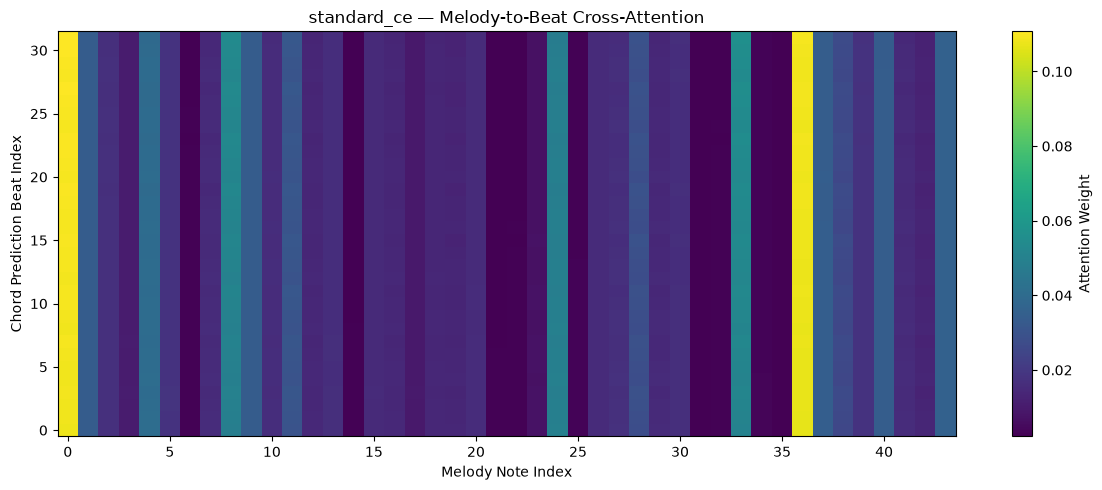

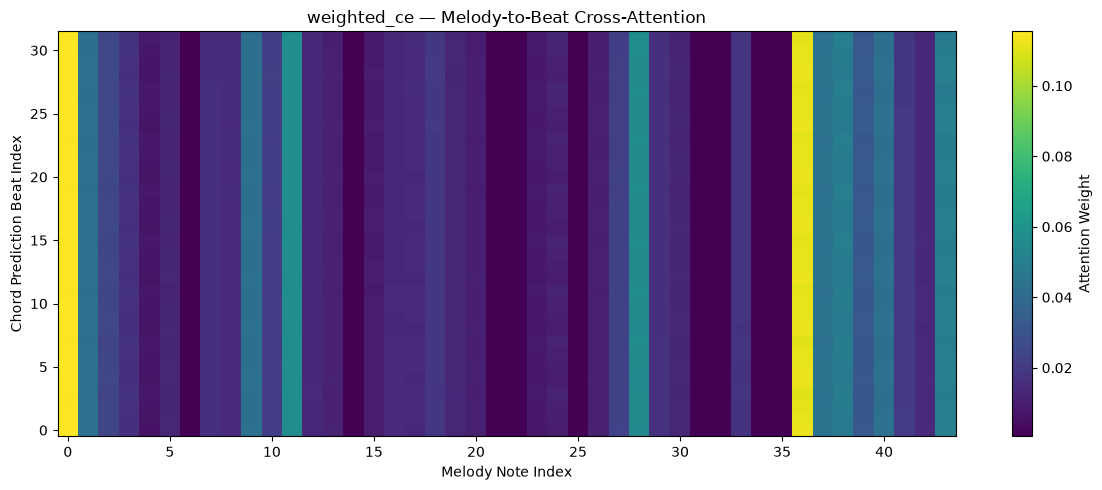


Cross-attention inspection completed!


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import islice


# -----------------------------------
# 1. Configuration
# -----------------------------------

NUM_ATTENTION_BATCHES = 8

# A beat is considered locally related
# to notes overlapping its own interval
# plus one neighboring beat on each side.

LOCAL_MARGIN_BEATS = 1.0


# -----------------------------------
# 2. Calculate local attention statistics
# -----------------------------------

def calculate_attention_locality(
    attention_matrix,
    note_features
):

    # attention_matrix:
    # [number_of_beats, number_of_notes]

    # note_features:
    # [number_of_notes, 3]
    #
    # Columns:
    # 0 = relative octave
    # 1 = onset in beats
    # 2 = duration in beats

    onsets = note_features[:, 1]

    durations = note_features[:, 2]

    offsets = onsets + durations

    num_beats, num_notes = (
        attention_matrix.shape
    )

    beat_indices = np.arange(num_beats)

    # -----------------------------------
    # Identify notes near each beat
    # -----------------------------------

    region_starts = (
        beat_indices - LOCAL_MARGIN_BEATS
    )

    region_ends = (
        beat_indices + 1 + LOCAL_MARGIN_BEATS
    )

    # A note is local if any part of its
    # duration overlaps the expanded beat.

    local_mask = (
        (onsets[None, :] < region_ends[:, None])
        &
        (offsets[None, :] > region_starts[:, None])
    )

    # -----------------------------------
    # Actual attention on nearby notes
    # -----------------------------------

    local_attention = (
        attention_matrix * local_mask
    ).sum(axis=1)

    # -----------------------------------
    # Expected attention if every note
    # received equal attention
    # -----------------------------------

    uniform_local_attention = (
        local_mask.sum(axis=1) / num_notes
    )

    return {
        "local_attention": local_attention,
        "uniform_local_attention": uniform_local_attention
    }


# -----------------------------------
# 3. Initialize statistics
# -----------------------------------

attention_statistics = {
    name: {
        "local_sum": 0.0,
        "uniform_sum": 0.0,
        "beat_count": 0
    }
    for name in best_models
}

mode_baseline_correct = 0
mode_baseline_total = 0


# -----------------------------------
# 4. Analyze validation windows
# -----------------------------------

with torch.no_grad():

    for val_batch in islice(
        val_loader,
        NUM_ATTENTION_BATCHES
    ):

        # Evaluate mode-only baseline
        # on the same validation subset.

        baseline_predictions = torch.where(
            val_batch["mode"][:, None] == 0,
            CHORD_TO_ID["I:MAJ"],
            CHORD_TO_ID["i:MIN"]
        ).expand_as(val_batch["eval_targets"])

        valid_targets = (
            val_batch["eval_targets"] != IGNORE_INDEX
        )

        mode_baseline_correct += (
            (baseline_predictions == val_batch["eval_targets"])
            & valid_targets
        ).sum().item()

        mode_baseline_total += (
            valid_targets.sum().item()
        )

        device_batch = move_batch(
            val_batch,
            DEVICE
        )

        # -----------------------------------
        # Analyze each trained model
        # -----------------------------------

        for name, current_model in best_models.items():

            current_model.eval()

            outputs = current_model(device_batch)

            attention = (
                outputs["attention_weights"]
                .detach()
                .cpu()
                .numpy()
            )

            for i in range(len(val_batch["mode"])):

                num_notes = int(
                    val_batch["note_lengths"][i]
                )

                num_beats = int(
                    val_batch["beat_lengths"][i]
                )

                weights = attention[
                    i,
                    :num_beats,
                    :num_notes
                ]

                features = (
                    val_batch["note_features"][
                        i, :num_notes
                    ]
                    .numpy()
                )

                # Each real beat should have
                # attention weights summing to 1.

                assert np.allclose(
                    weights.sum(axis=1),
                    1.0,
                    atol=1e-4
                )

                locality = calculate_attention_locality(
                    weights,
                    features
                )

                stats = attention_statistics[name]

                stats["local_sum"] += (
                    locality["local_attention"].sum()
                )

                stats["uniform_sum"] += (
                    locality["uniform_local_attention"].sum()
                )

                stats["beat_count"] += num_beats


# -----------------------------------
# 5. Display aggregate statistics
# -----------------------------------

summary_rows = []

for name, stats in attention_statistics.items():

    average_local = (
        stats["local_sum"] / stats["beat_count"]
    )

    average_uniform = (
        stats["uniform_sum"] / stats["beat_count"]
    )

    summary_rows.append({
        "Model": name,

        "Attention on nearby notes %":
            average_local * 100,

        "Uniform-attention baseline %":
            average_uniform * 100,

        "Local attention ratio":
            average_local / max(average_uniform, 1e-9)
    })


print("CROSS-ATTENTION LOCALITY ANALYSIS")
print("--------------------------------")

print(
    "Validation batches:",
    NUM_ATTENTION_BATCHES
)

print(
    "Mode-only baseline accuracy on this subset:",
    f"{100 * mode_baseline_correct / mode_baseline_total:.2f}%"
)

display(
    pd.DataFrame(summary_rows).round(3)
)


# -----------------------------------
# 6. Visualize a representative window
# -----------------------------------

# Use the major-key window selected
# during the earlier chord inspection.

selected = selected_windows[0]

example_index = selected["dataset_index"]

example = val_dataset[example_index]

single_batch = collate_melody_chord(
    [example]
)

device_batch = move_batch(
    single_batch,
    DEVICE
)

num_notes = int(
    single_batch["note_lengths"][0]
)

num_beats = int(
    single_batch["beat_lengths"][0]
)

print("\nATTENTION VISUALIZATION")
print("--------------------------------")

print("Track:", example["track_id"])
print("Melody notes:", num_notes)
print("Beats:", num_beats)


# -----------------------------------
# 7. Create attention heatmaps
# -----------------------------------

for name, current_model in best_models.items():

    current_model.eval()

    with torch.no_grad():

        outputs = current_model(
            device_batch
        )

    attention = (
        outputs["attention_weights"][
            0,
            :num_beats,
            :num_notes
        ]
        .cpu()
        .numpy()
    )

    plt.figure(figsize=(12, 5))

    plt.imshow(
        attention,
        aspect="auto",
        origin="lower",
        interpolation="nearest"
    )

    plt.title(
        f"{name} — Melody-to-Beat Cross-Attention"
    )

    plt.xlabel("Melody Note Index")
    plt.ylabel("Chord Prediction Beat Index")

    plt.colorbar(
        label="Attention Weight"
    )

    plt.tight_layout()
    plt.show()


print("\nCross-attention inspection completed!")

### Prototype Temporal Attention Bias

TEMPORAL ATTENTION PROTOTYPE
--------------------------------
Track: track_1078438
Melody notes: 44
Beats: 32
Temporal sigma: 2.0

Attention on nearby notes: 58.50%
Uniform-attention baseline: 10.80%
Local attention ratio: 5.419


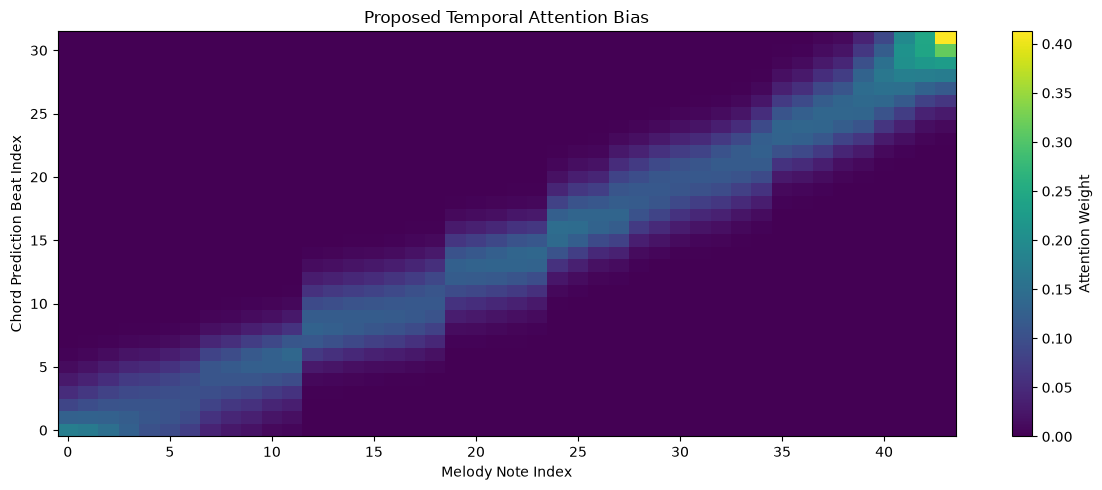


Temporal attention prototype completed!


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# -----------------------------------
# 1. Select the same example window
# -----------------------------------

selected = selected_windows[0]

example = val_dataset[
    selected["dataset_index"]
]

note_features = (
    example["note_features"]
    .numpy()
)

num_notes = len(
    example["note_pitch_classes"]
)

num_beats = len(
    example["beat_features"]
)


# -----------------------------------
# 2. Extract note timing
# -----------------------------------

# note_features:
# 0 = Relative octave
# 1 = Onset in beats
# 2 = Duration in beats

note_onsets = note_features[:, 1]

note_durations = note_features[:, 2]

note_offsets = (
    note_onsets + note_durations
)


# -----------------------------------
# 3. Define beat centers
# -----------------------------------

beat_centers = (
    example["beat_features"][:, 0]
    .numpy()
    + 0.5
)


# -----------------------------------
# 4. Calculate beat-to-note distance
# -----------------------------------

# Distance is zero if the note overlaps
# the center of the beat.
#
# Otherwise, measure the distance to
# the nearest edge of the note.

distance_before = (
    note_onsets[None, :]
    - beat_centers[:, None]
)

distance_after = (
    beat_centers[:, None]
    - note_offsets[None, :]
)

distances = np.maximum(
    np.maximum(
        distance_before,
        distance_after
    ),
    0.0
)


# -----------------------------------
# 5. Construct temporal attention bias
# -----------------------------------

# Larger sigma allows attention
# to spread across more beats.

TEMPORAL_SIGMA = 2.0

temporal_bias = (
    -0.5
    * (distances / TEMPORAL_SIGMA) ** 2
)


# -----------------------------------
# 6. Convert bias into an attention
#    distribution using softmax
# -----------------------------------

stable_bias = (
    temporal_bias
    - temporal_bias.max(
        axis=1,
        keepdims=True
    )
)

exp_bias = np.exp(stable_bias)

temporal_attention = (
    exp_bias
    / exp_bias.sum(
        axis=1,
        keepdims=True
    )
)


# -----------------------------------
# 7. Validate attention distribution
# -----------------------------------

assert temporal_attention.shape == (
    num_beats,
    num_notes
)

assert np.isfinite(
    temporal_attention
).all()

assert np.allclose(
    temporal_attention.sum(axis=1),
    1.0,
    atol=1e-5
)


# -----------------------------------
# 8. Calculate attention locality
# -----------------------------------

locality = calculate_attention_locality(
    temporal_attention,
    note_features
)

average_local = (
    locality["local_attention"]
    .mean()
)

average_uniform = (
    locality["uniform_local_attention"]
    .mean()
)

locality_ratio = (
    average_local / average_uniform
)


# -----------------------------------
# 9. Display results
# -----------------------------------

print("TEMPORAL ATTENTION PROTOTYPE")
print("--------------------------------")

print("Track:", example["track_id"])

print("Melody notes:", num_notes)
print("Beats:", num_beats)

print(
    "Temporal sigma:",
    TEMPORAL_SIGMA
)

print(
    "\nAttention on nearby notes:",
    f"{average_local * 100:.2f}%"
)

print(
    "Uniform-attention baseline:",
    f"{average_uniform * 100:.2f}%"
)

print(
    "Local attention ratio:",
    round(locality_ratio, 3)
)


# -----------------------------------
# 10. Visualize temporal attention
# -----------------------------------

plt.figure(figsize=(12, 5))

plt.imshow(
    temporal_attention,
    aspect="auto",
    origin="lower",
    interpolation="nearest"
)

plt.title(
    "Proposed Temporal Attention Bias"
)

plt.xlabel("Melody Note Index")

plt.ylabel("Chord Prediction Beat Index")

plt.colorbar(
    label="Attention Weight"
)

plt.tight_layout()
plt.show()


print(
    "\nTemporal attention prototype completed!"
)

### Temporal Cross-Attention Module

In [34]:
import copy
import torch
import torch.nn as nn


# -----------------------------------
# 1. Temporal cross-attention
# -----------------------------------

class TemporalBeatQueryCrossAttention(nn.Module):

    def __init__(
        self,
        original_attention,
        sigma=2.0,
        strength=1.0
    ):
        super().__init__()

        # Reuse the original trainable layers
        # so we can compare fairly.

        self.beat_projection = copy.deepcopy(
            original_attention.beat_projection
        )

        self.mode_embedding = copy.deepcopy(
            original_attention.mode_embedding
        )

        self.cross_attention = copy.deepcopy(
            original_attention.cross_attention
        )

        # Find the original normalization layer.
        norm_layers = [
            layer
            for layer in original_attention.modules()
            if isinstance(layer, nn.LayerNorm)
        ]

        assert len(norm_layers) == 1

        self.layer_norm = copy.deepcopy(
            norm_layers[0]
        )

        dropout_layers = [
            layer
            for layer in original_attention.children()
            if isinstance(layer, nn.Dropout)
        ]

        assert len(dropout_layers) == 1

        self.dropout = copy.deepcopy(
            dropout_layers[0]
        )

        self.num_heads = (
            self.cross_attention.num_heads
        )

        self.sigma = sigma
        self.strength = strength


    def forward(
        self,
        contextual_notes,
        note_features,
        beat_features,
        modes,
        beat_lengths,
        note_padding_mask,
        beat_padding_mask
    ):

        batch_size = beat_features.shape[0]

        # -----------------------------------
        # A. Construct beat queries
        # -----------------------------------

        normalized_beat_position = (
            beat_features[:, :, 0:1]
            / beat_lengths[:, None, None]
              .clamp(min=1)
        )

        beats_per_bar = (
            beat_features[:, :, 1]
            .amax(dim=1)
            .view(batch_size, 1, 1)
            .clamp(min=1)
        )

        normalized_bar_position = (
            (beat_features[:, :, 1:2] - 1)
            / beats_per_bar
        )

        query_features = torch.cat(
            [
                normalized_beat_position,
                normalized_bar_position
            ],
            dim=-1
        )

        queries = (
            self.beat_projection(query_features)
            + self.mode_embedding(modes)[:, None, :]
        )

        # -----------------------------------
        # B. Calculate temporal distance
        # -----------------------------------

        note_onsets = note_features[:, :, 1]
        note_offsets = (
            note_onsets + note_features[:, :, 2]
        )

        beat_centers = (
            beat_features[:, :, 0] + 0.5
        )

        distances = torch.maximum(
            torch.maximum(
                note_onsets[:, None, :]
                - beat_centers[:, :, None],

                beat_centers[:, :, None]
                - note_offsets[:, None, :]
            ),
            torch.zeros_like(
                beat_centers[:, :, None]
            )
        )

        # -----------------------------------
        # C. Gaussian temporal bias
        # -----------------------------------

        temporal_bias = (
            -0.5
            * self.strength
            * (distances / self.sigma).square()
        )

        # Prevent attention to padded notes.
        # This is incorporated directly into
        # the additive attention mask.

        temporal_bias = temporal_bias.masked_fill(
            note_padding_mask[:, None, :],
            -1e4
        )

        # PyTorch expects one attention mask
        # per batch item and attention head.

        attention_mask = (
            temporal_bias.repeat_interleave(
                self.num_heads,
                dim=0
            )
        )

        # -----------------------------------
        # D. Cross-attention
        # -----------------------------------

        attended, attention_weights = (
            self.cross_attention(
                query=queries,
                key=contextual_notes,
                value=contextual_notes,
                attn_mask=attention_mask,
                need_weights=True
            )
        )

        # -----------------------------------
        # E. Residual connection and norm
        # -----------------------------------

        beat_representations = self.layer_norm(
            queries + self.dropout(attended)
        )

        beat_representations = (
            beat_representations.masked_fill(
                beat_padding_mask.unsqueeze(-1),
                0.0
            )
        )

        return (
            beat_representations,
            attention_weights
        )


# -----------------------------------
# 2. Create temporal attention module
# -----------------------------------

# fresh_model is our original untrained
# model from Cell 23.

original_attention = (
    fresh_model.beat_attention
)

temporal_attention_layer = (
    TemporalBeatQueryCrossAttention(
        original_attention=original_attention,
        sigma=2.0,
        strength=1.0
    )
)


# -----------------------------------
# 3. Prepare an example window
# -----------------------------------

example = val_dataset[
    selected_windows[0]["dataset_index"]
]

sample_batch = collate_melody_chord(
    [example]
)

fresh_model.eval()
temporal_attention_layer.eval()


# -----------------------------------
# 4. Generate contextual melody notes
# -----------------------------------

with torch.no_grad():

    embedded = fresh_model.note_embedding(
        note_pitch_classes=sample_batch[
            "note_pitch_classes"
        ],
        note_features=sample_batch[
            "note_features"
        ],
        modes=sample_batch["mode"],
        beat_lengths=sample_batch["beat_lengths"],
        note_padding_mask=sample_batch[
            "note_padding_mask"
        ]
    )

    contextual = fresh_model.melody_encoder(
        note_embeddings=embedded,
        note_padding_mask=sample_batch[
            "note_padding_mask"
        ]
    )


# -----------------------------------
# 5. Verify the original behavior
#    when temporal strength is zero
# -----------------------------------

with torch.no_grad():

    original_output, original_weights = (
        original_attention(
            contextual_notes=contextual,
            beat_features=sample_batch[
                "beat_features"
            ],
            modes=sample_batch["mode"],
            beat_lengths=sample_batch[
                "beat_lengths"
            ],
            note_padding_mask=sample_batch[
                "note_padding_mask"
            ],
            beat_padding_mask=sample_batch[
                "beat_padding_mask"
            ]
        )
    )

    temporal_attention_layer.strength = 0.0

    zero_bias_output, zero_bias_weights = (
        temporal_attention_layer(
            contextual_notes=contextual,
            note_features=sample_batch[
                "note_features"
            ],
            beat_features=sample_batch[
                "beat_features"
            ],
            modes=sample_batch["mode"],
            beat_lengths=sample_batch[
                "beat_lengths"
            ],
            note_padding_mask=sample_batch[
                "note_padding_mask"
            ],
            beat_padding_mask=sample_batch[
                "beat_padding_mask"
            ]
        )
    )


output_difference = (
    original_output - zero_bias_output
).abs().max().item()

weight_difference = (
    original_weights - zero_bias_weights
).abs().max().item()

print("ZERO-BIAS EQUIVALENCE TEST")
print("--------------------------------")

print(
    "Maximum output difference:",
    round(output_difference, 8)
)

print(
    "Maximum attention difference:",
    round(weight_difference, 8)
)


# -----------------------------------
# 6. Enable temporal bias
# -----------------------------------

temporal_attention_layer.strength = 1.0

with torch.no_grad():

    temporal_output, temporal_weights = (
        temporal_attention_layer(
            contextual_notes=contextual,
            note_features=sample_batch[
                "note_features"
            ],
            beat_features=sample_batch[
                "beat_features"
            ],
            modes=sample_batch["mode"],
            beat_lengths=sample_batch[
                "beat_lengths"
            ],
            note_padding_mask=sample_batch[
                "note_padding_mask"
            ],
            beat_padding_mask=sample_batch[
                "beat_padding_mask"
            ]
        )
    )


# -----------------------------------
# 7. Validate dimensions
# -----------------------------------

print("\nTEMPORAL CROSS-ATTENTION")
print("--------------------------------")

print(
    "Contextual notes:",
    tuple(contextual.shape)
)

print(
    "Output beats:",
    tuple(temporal_output.shape)
)

print(
    "Attention weights:",
    tuple(temporal_weights.shape)
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in temporal_attention_layer.parameters()
    )
)

assert torch.isfinite(
    temporal_output
).all()

assert torch.isfinite(
    temporal_weights
).all()

assert torch.allclose(
    temporal_weights.sum(dim=-1),
    torch.ones_like(
        temporal_weights.sum(dim=-1)
    ),
    atol=1e-5
)


# -----------------------------------
# 8. Compare attention locality
# -----------------------------------

features = (
    sample_batch["note_features"][0]
    .numpy()
)

original_locality = calculate_attention_locality(
    original_weights[0].numpy(),
    features
)

temporal_locality = calculate_attention_locality(
    temporal_weights[0].numpy(),
    features
)

print("\nLOCALITY COMPARISON")
print("--------------------------------")

print(
    "Original nearby attention:",
    f"{original_locality['local_attention'].mean() * 100:.2f}%"
)

print(
    "Temporal nearby attention:",
    f"{temporal_locality['local_attention'].mean() * 100:.2f}%"
)

print("\nModule test completed!")

ZERO-BIAS EQUIVALENCE TEST
--------------------------------
Maximum output difference: 0.0
Maximum attention difference: 0.0

TEMPORAL CROSS-ATTENTION
--------------------------------
Contextual notes: (1, 44, 128)
Output beats: (1, 32, 128)
Attention weights: (1, 32, 44)
Trainable parameters: 83456

LOCALITY COMPARISON
--------------------------------
Original nearby attention: 10.87%
Temporal nearby attention: 58.60%

Module test completed!


### Complete Temporal Transformer

In [35]:
import copy
import torch
import torch.nn as nn


# -----------------------------------
# 1. Complete Temporal Transformer
# -----------------------------------

class TemporalMelodyChordTransformer(nn.Module):

    def __init__(
        self,
        reference_model,
        sigma=2.0,
        strength=1.0
    ):

        super().__init__()

        # -----------------------------------
        # A. Note embedding
        # -----------------------------------

        self.note_embedding = copy.deepcopy(
            reference_model.note_embedding
        )

        # -----------------------------------
        # B. Melody encoder
        # -----------------------------------

        self.melody_encoder = copy.deepcopy(
            reference_model.melody_encoder
        )

        # -----------------------------------
        # C. Temporal cross-attention
        # -----------------------------------

        self.beat_attention = (
            TemporalBeatQueryCrossAttention(
                original_attention=(
                    reference_model.beat_attention
                ),
                sigma=sigma,
                strength=strength
            )
        )

        # -----------------------------------
        # D. Beat sequence encoder
        # -----------------------------------

        self.beat_encoder = copy.deepcopy(
            reference_model.beat_encoder
        )

        # -----------------------------------
        # E. Chord prediction head
        # -----------------------------------

        self.chord_head = copy.deepcopy(
            reference_model.chord_head
        )


    def forward(self, batch):

        # -----------------------------------
        # 1. Embed melody notes
        # -----------------------------------

        note_embeddings = self.note_embedding(
            note_pitch_classes=batch["note_pitch_classes"],
            note_features=batch["note_features"],
            modes=batch["mode"],
            beat_lengths=batch["beat_lengths"],
            note_padding_mask=batch["note_padding_mask"]
        )

        # -----------------------------------
        # 2. Encode melody
        # -----------------------------------

        contextual_notes = self.melody_encoder(
            note_embeddings=note_embeddings,
            note_padding_mask=batch["note_padding_mask"]
        )

        # -----------------------------------
        # 3. Temporal cross-attention
        # -----------------------------------

        # IMPORTANT CHANGE:
        # We now explicitly pass note_features
        # to calculate note-to-beat distances.

        beat_representations, attention_weights = (
            self.beat_attention(
                contextual_notes=contextual_notes,
                note_features=batch["note_features"],
                beat_features=batch["beat_features"],
                modes=batch["mode"],
                beat_lengths=batch["beat_lengths"],
                note_padding_mask=batch["note_padding_mask"],
                beat_padding_mask=batch["beat_padding_mask"]
            )
        )

        # -----------------------------------
        # 4. Encode beat sequence
        # -----------------------------------

        contextual_beats = self.beat_encoder(
            beat_representations=beat_representations,
            beat_padding_mask=batch["beat_padding_mask"]
        )

        # -----------------------------------
        # 5. Predict chords
        # -----------------------------------

        logits = self.chord_head(
            contextual_beats=contextual_beats,
            beat_padding_mask=batch["beat_padding_mask"]
        )

        return {
            "logits": logits,
            "attention_weights": attention_weights
        }


# -----------------------------------
# 2. Create reference baseline model
# -----------------------------------

# fresh_model was initialized in Cell 23.
# Unlike model_ce, it has NOT been trained.
#
# Create a copy to preserve its weights.

reference_model = copy.deepcopy(
    fresh_model
).to(DEVICE)

reference_model.eval()


# -----------------------------------
# 3. Create Temporal Transformer
# -----------------------------------

temporal_model = (
    TemporalMelodyChordTransformer(
        reference_model=reference_model,
        sigma=2.0,
        strength=1.0
    )
).to(DEVICE)

temporal_model.eval()


# -----------------------------------
# 4. Prepare sample batch
# -----------------------------------

# Use the sample from Cell 29.

test_batch = move_batch(
    sample_batch,
    DEVICE
)


# -----------------------------------
# 5. Test zero-bias equivalence
#    across the COMPLETE network
# -----------------------------------

temporal_model.beat_attention.strength = 0.0

with torch.no_grad():

    reference_outputs = reference_model(
        test_batch
    )

    zero_bias_outputs = temporal_model(
        test_batch
    )


max_difference = (
    reference_outputs["logits"]
    - zero_bias_outputs["logits"]
).abs().max().item()


print("COMPLETE MODEL EQUIVALENCE")
print("--------------------------------")

print(
    "Maximum logits difference:",
    round(max_difference, 8)
)

assert torch.allclose(
    reference_outputs["logits"],
    zero_bias_outputs["logits"],
    atol=1e-5,
    rtol=1e-5
)


# -----------------------------------
# 6. Enable temporal attention
# -----------------------------------

temporal_model.beat_attention.strength = 1.0

with torch.no_grad():

    temporal_outputs = temporal_model(
        test_batch
    )


# -----------------------------------
# 7. Verify output shapes
# -----------------------------------

logits = temporal_outputs["logits"]

attention = temporal_outputs["attention_weights"]


print("\nCOMPLETE TEMPORAL TRANSFORMER")
print("--------------------------------")

print(
    "Input melody shape:",
    tuple(test_batch["note_pitch_classes"].shape)
)

print(
    "Output chord logits:",
    tuple(logits.shape)
)

print(
    "Attention weights:",
    tuple(attention.shape)
)


# -----------------------------------
# 8. Compare parameter counts
# -----------------------------------

original_parameters = sum(
    p.numel()
    for p in reference_model.parameters()
)

temporal_parameters = sum(
    p.numel()
    for p in temporal_model.parameters()
)

print("\nPARAMETER COMPARISON")
print("--------------------------------")

print(
    "Original Transformer:",
    original_parameters
)

print(
    "Temporal Transformer:",
    temporal_parameters
)

assert (
    original_parameters
    == temporal_parameters
    == 640699
)


# -----------------------------------
# 9. Validate outputs
# -----------------------------------

assert logits.shape == (
    1,
    test_batch["beat_features"].shape[1],
    NUM_CHORD_CLASSES
)

assert torch.isfinite(logits).all()

assert torch.isfinite(attention).all()

assert torch.allclose(
    attention.sum(dim=-1),
    torch.ones_like(
        attention.sum(dim=-1)
    ),
    atol=1e-5
)


# -----------------------------------
# 10. Verify gradient flow
# -----------------------------------

temporal_model.train()

temporal_model.zero_grad(set_to_none=True)

training_logits = temporal_model(
    test_batch
)["logits"]

training_loss = loss_ce(
    training_logits.transpose(1, 2),
    test_batch["chord_targets"]
)

training_loss.backward()


components = {
    "Note Embedding":
        temporal_model.note_embedding,

    "Melody Encoder":
        temporal_model.melody_encoder,

    "Temporal Cross-Attention":
        temporal_model.beat_attention,

    "Beat Encoder":
        temporal_model.beat_encoder,

    "Chord Prediction Head":
        temporal_model.chord_head
}


print("\nGRADIENT FLOW")
print("--------------------------------")

for name, component in components.items():

    gradient_norm = sum(
        p.grad.norm().item()
        for p in component.parameters()
        if p.grad is not None
    )

    print(
        f"{name:26s}: {gradient_norm:.6f}"
    )

    assert gradient_norm > 0


# -----------------------------------
# 11. Clean up test gradients
# -----------------------------------

temporal_model.zero_grad(set_to_none=True)

temporal_model.eval()


print("\nVALIDATION")
print("--------------------------------")

print("Complete forward pass: PASSED")
print("Zero-bias equivalence: PASSED")
print("Parameter count: PASSED")
print("Gradient flow: PASSED")

print("\nTemporal Transformer ready for training!")

COMPLETE MODEL EQUIVALENCE
--------------------------------
Maximum logits difference: 0.0

COMPLETE TEMPORAL TRANSFORMER
--------------------------------
Input melody shape: (1, 44)
Output chord logits: (1, 32, 59)
Attention weights: (1, 32, 44)

PARAMETER COMPARISON
--------------------------------
Original Transformer: 640699
Temporal Transformer: 640699

GRADIENT FLOW
--------------------------------
Note Embedding            : 0.419610
Melody Encoder            : 2.922572
Temporal Cross-Attention  : 5.854073
Beat Encoder              : 18.884949
Chord Prediction Head     : 6.493724

VALIDATION
--------------------------------
Complete forward pass: PASSED
Zero-bias equivalence: PASSED
Parameter count: PASSED
Gradient flow: PASSED

Temporal Transformer ready for training!


### Train the Temporal Transformer

In [36]:
import torch
import pandas as pd
import numpy as np


# -----------------------------------
# 1. Experiment configuration
# -----------------------------------

TEMPORAL_EPOCHS = 8

TEMPORAL_SIGMA = 2.0
TEMPORAL_STRENGTH = 1.0

# Ensure temporal bias is enabled
temporal_model.beat_attention.sigma = TEMPORAL_SIGMA
temporal_model.beat_attention.strength = TEMPORAL_STRENGTH


# -----------------------------------
# 2. Create optimizer
# -----------------------------------

temporal_optimizer = torch.optim.AdamW(
    temporal_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# -----------------------------------
# 3. Create fresh training loader
# -----------------------------------

# IMPORTANT:
# Use a new DataLoader with the original
# seed so the shuffle order matches
# our earlier standard CE experiment.

temporal_train_loader = make_train_loader(
    EXPERIMENT_SEED
)


# -----------------------------------
# 4. Initialize tracking
# -----------------------------------

temporal_history = []

best_temporal_f1 = -1.0
best_temporal_epoch = None

temporal_checkpoint_path = (
    CHECKPOINT_DIR / "temporal_ce_best.pt"
)


# -----------------------------------
# 5. Train for 8 epochs
# -----------------------------------

print("TEMPORAL TRANSFORMER TRAINING")
print("=" * 65)

print("Temporal sigma:", TEMPORAL_SIGMA)
print("Temporal strength:", TEMPORAL_STRENGTH)
print("Epochs:", TEMPORAL_EPOCHS)

print("\nStarting training...")


for epoch in range(1, TEMPORAL_EPOCHS + 1):

    # Match the randomness used in Cell 24
    torch.manual_seed(
        EXPERIMENT_SEED + epoch
    )

    # -----------------------------------
    # A. Train
    # -----------------------------------

    train_metrics = train_experiment_epoch(
        model=temporal_model,
        loader=temporal_train_loader,
        optimizer=temporal_optimizer,
        criterion=loss_ce
    )

    # -----------------------------------
    # B. Validate
    # -----------------------------------

    val_metrics = evaluate_experiment(
        model=temporal_model,
        loader=val_loader
    )

    # -----------------------------------
    # C. Record results
    # -----------------------------------

    result = {
        "experiment": "temporal_ce",
        "epoch": epoch,
        **train_metrics,
        **val_metrics
    }

    temporal_history.append(result)

    # -----------------------------------
    # D. Display results
    # -----------------------------------

    print(f"\nEPOCH {epoch}/{TEMPORAL_EPOCHS}")
    print("--------------------------------")

    print(
        f"Training loss:     "
        f"{train_metrics['train_loss']:.4f}"
    )

    print(
        f"Training accuracy: "
        f"{train_metrics['train_accuracy'] * 100:.2f}%"
    )

    print(
        f"Validation loss:   "
        f"{val_metrics['val_loss']:.4f}"
    )

    print(
        f"Validation accuracy: "
        f"{val_metrics['val_accuracy'] * 100:.2f}%"
    )

    print(
        f"Macro-F1:          "
        f"{val_metrics['macro_f1']:.4f}"
    )

    print(
        f"Chord-change F1:   "
        f"{val_metrics['change_f1']:.4f}"
    )

    print(
        f"Unique chords:     "
        f"{val_metrics['unique_chords']}"
    )

    print(
        f"Tonic predictions: "
        f"{val_metrics['tonic_percentage']:.2f}%"
    )

    # -----------------------------------
    # E. Save best checkpoint
    # -----------------------------------

    if val_metrics["macro_f1"] > best_temporal_f1:

        best_temporal_f1 = (
            val_metrics["macro_f1"]
        )

        best_temporal_epoch = epoch

        # Convert NumPy scalars to native
        # Python values for safe checkpoint
        # loading with weights_only=True.

        safe_metrics = {
            key: (
                value.item()
                if isinstance(value, np.generic)
                else value
            )
            for key, value in val_metrics.items()
        }

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    temporal_model.state_dict(),

                "optimizer_state_dict":
                    temporal_optimizer.state_dict(),

                "validation_metrics":
                    safe_metrics,

                "chord_labels":
                    CHORD_LABELS,

                "temporal_sigma":
                    TEMPORAL_SIGMA,

                "temporal_strength":
                    TEMPORAL_STRENGTH,

                "dataset_version":
                    dataset_config["version"]
            },
            temporal_checkpoint_path
        )

        print("Best checkpoint updated!")


# -----------------------------------
# 6. Create training history
# -----------------------------------

temporal_history_df = pd.DataFrame(
    temporal_history
)

print("\n" + "=" * 65)
print("COMPLETE TEMPORAL TRAINING HISTORY")
print("=" * 65)

display(
    temporal_history_df.round(4)
)


# -----------------------------------
# 7. Find best temporal checkpoint
# -----------------------------------

best_temporal_row = (
    temporal_history_df
    .sort_values(
        ["macro_f1", "epoch"],
        ascending=[False, True]
    )
    .iloc[0]
)


# -----------------------------------
# 8. Retrieve original baseline results
# -----------------------------------

standard_history = history_df[
    history_df["experiment"] == "standard_ce"
]

best_standard_row = (
    standard_history
    .sort_values(
        ["macro_f1", "epoch"],
        ascending=[False, True]
    )
    .iloc[0]
)


# -----------------------------------
# 9. Compare both architectures
# -----------------------------------

comparison_rows = []

for name, row in [
    ("Standard Transformer", best_standard_row),
    ("Temporal Transformer", best_temporal_row)
]:

    comparison_rows.append({
        "Model": name,

        "Best epoch":
            int(row["epoch"]),

        "Validation accuracy %":
            float(row["val_accuracy"]) * 100,

        "Macro-F1":
            float(row["macro_f1"]),

        "Chord-change F1":
            float(row["change_f1"]),

        "Unique chords":
            int(row["unique_chords"]),

        "Tonic predictions %":
            float(row["tonic_percentage"]),

        "Validation loss":
            float(row["val_loss"])
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 65)
print("ARCHITECTURAL ABLATION RESULTS")
print("=" * 65)

display(
    comparison_df.round(4)
)


# -----------------------------------
# 10. Calculate improvement
# -----------------------------------

accuracy_difference = (
    best_temporal_row["val_accuracy"]
    - best_standard_row["val_accuracy"]
) * 100

macro_f1_difference = (
    best_temporal_row["macro_f1"]
    - best_standard_row["macro_f1"]
)

change_f1_difference = (
    best_temporal_row["change_f1"]
    - best_standard_row["change_f1"]
)


print("\nTEMPORAL VS STANDARD")
print("--------------------------------")

print(
    f"Accuracy difference: "
    f"{accuracy_difference:+.2f} percentage points"
)

print(
    f"Macro-F1 difference: "
    f"{macro_f1_difference:+.4f}"
)

print(
    f"Chord-change F1 difference: "
    f"{change_f1_difference:+.4f}"
)

print(
    "\nBest temporal epoch:",
    best_temporal_epoch
)

print(
    "Best checkpoint:",
    temporal_checkpoint_path.name
)

print("\nTemporal training completed!")

TEMPORAL TRANSFORMER TRAINING
Temporal sigma: 2.0
Temporal strength: 1.0
Epochs: 8

Starting training...

EPOCH 1/8
--------------------------------
Training loss:     2.0306
Training accuracy: 46.74%
Validation loss:   1.7711
Validation accuracy: 53.98%
Macro-F1:          0.0453
Chord-change F1:   0.0370
Unique chords:     5
Tonic predictions: 92.81%
Best checkpoint updated!

EPOCH 2/8
--------------------------------
Training loss:     1.8181
Training accuracy: 48.25%
Validation loss:   1.6961
Validation accuracy: 55.05%
Macro-F1:          0.0423
Chord-change F1:   0.0187
Unique chords:     6
Tonic predictions: 96.53%

EPOCH 3/8
--------------------------------
Training loss:     1.7757
Training accuracy: 48.67%
Validation loss:   1.6975
Validation accuracy: 52.05%
Macro-F1:          0.0560
Chord-change F1:   0.0613
Unique chords:     10
Tonic predictions: 79.68%
Best checkpoint updated!

EPOCH 4/8
--------------------------------
Training loss:     1.7450
Training accuracy: 48.86%
V

,experiment,epoch,train_loss,train_accuracy,val_loss,val_accuracy,macro_f1,change_f1,unique_chords,tonic_percentage
0,temporal_ce,1,2.0306,0.4674,1.7711,0.5398,0.0453,0.0370,5,92.8068
1,temporal_ce,2,1.8181,0.4825,1.6961,0.5505,0.0423,0.0187,6,96.5334
2,temporal_ce,3,1.7757,0.4867,1.6975,0.5205,0.0560,0.0613,10,79.6752
3,temporal_ce,4,1.7450,0.4886,1.6832,0.5354,0.0581,0.0711,10,82.6482
4,temporal_ce,5,1.7219,0.4910,1.6737,0.5353,0.0591,0.0596,9,81.1334
5,temporal_ce,6,1.6955,0.4953,1.7065,0.5357,0.0654,0.0657,15,83.9670
6,temporal_ce,7,1.6740,0.4993,1.6819,0.5365,0.0648,0.0547,13,85.8397
7,temporal_ce,8,1.6516,0.5009,1.7174,0.5256,0.0607,0.0717,20,83.7296



ARCHITECTURAL ABLATION RESULTS


,Model,Best epoch,Validation accuracy %,Macro-F1,Chord-change F1,Unique chords,Tonic predictions %,Validation loss
0,Standard Transformer,5,53.2311,0.0432,0.0052,7,92.788,1.7322
1,Temporal Transformer,6,53.5702,0.0654,0.0657,15,83.967,1.7065



TEMPORAL VS STANDARD
--------------------------------
Accuracy difference: +0.34 percentage points
Macro-F1 difference: +0.0222
Chord-change F1 difference: +0.0605

Best temporal epoch: 6
Best checkpoint: temporal_ce_best.pt

Temporal training completed!


In [37]:
import copy
import torch
import pandas as pd


# -----------------------------------
# 1. Load best temporal checkpoint
# -----------------------------------

checkpoint = torch.load(
    temporal_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

best_temporal_model = copy.deepcopy(
    temporal_model
)

best_temporal_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_temporal_model = (
    best_temporal_model.to(DEVICE)
)

best_temporal_model.eval()

print(
    "Best temporal checkpoint:",
    checkpoint["epoch"]
)


# -----------------------------------
# 2. Models to compare
# -----------------------------------

inspection_models = {
    "Standard CE": best_models["standard_ce"],
    "Temporal CE": best_temporal_model
}


# -----------------------------------
# 3. Inspect selected validation windows
# -----------------------------------

for selected in selected_windows:

    index = selected["dataset_index"]

    example = val_dataset[index]

    sample = collate_melody_chord(
        [example]
    )

    device_sample = move_batch(
        sample,
        DEVICE
    )

    predictions = {}

    # -----------------------------------
    # A. Predict using both models
    # -----------------------------------

    with torch.no_grad():

        for name, current_model in (
            inspection_models.items()
        ):

            current_model.eval()

            logits = current_model(
                device_sample
            )["logits"]

            predictions[name] = (
                logits.argmax(dim=-1)[0]
                .cpu()
                .tolist()
            )

    # -----------------------------------
    # B. Get reference chords
    # -----------------------------------

    actual = example[
        "eval_targets"
    ].tolist()

    # -----------------------------------
    # C. Build comparison table
    # -----------------------------------

    comparison = pd.DataFrame({
        "Beat": range(1, len(actual) + 1),

        "Actual": [
            chord_name(c)
            for c in actual
        ],

        "Standard CE": [
            chord_name(c)
            for c in predictions["Standard CE"]
        ],

        "Temporal CE": [
            chord_name(c)
            for c in predictions["Temporal CE"]
        ]
    })

    # -----------------------------------
    # D. Display
    # -----------------------------------

    print("\n" + "=" * 65)

    print(
        "TRACK:",
        example["track_id"]
    )

    print(
        "MODE:",
        MODE_NAMES[
            int(example["mode"].item())
        ]
    )

    print("=" * 65)

    display(comparison)

    # -----------------------------------
    # E. Calculate window accuracy
    # -----------------------------------

    valid = [
        i for i, c in enumerate(actual)
        if c != IGNORE_INDEX
    ]

    print("\nWINDOW ACCURACY")
    print("--------------------------------")

    for name, predicted in predictions.items():

        correct = sum(
            predicted[i] == actual[i]
            for i in valid
        )

        accuracy = (
            100 * correct / len(valid)
        )

        unique = len(
            set(predicted)
        )

        print(
            f"{name:15s} | "
            f"Accuracy: {accuracy:6.2f}% | "
            f"Unique chords: {unique}"
        )


print("\nTemporal prediction inspection completed!")

Best temporal checkpoint: 6

TRACK: track_1078438
MODE: Major


,Beat,Actual,Standard CE,Temporal CE
0,1,ii:MIN,I:MAJ,I:MAJ
1,2,MASKED,I:MAJ,I:MAJ
2,3,V:DOM7,I:MAJ,I:MAJ
3,4,V:DOM7,I:MAJ,I:MAJ
4,5,I:MAJ,I:MAJ,I:MAJ
5,6,I:MAJ,I:MAJ,I:MAJ
6,7,IV:MAJ,I:MAJ,I:MAJ
7,8,IV:MAJ,I:MAJ,I:MAJ
8,9,ii:MIN,I:MAJ,I:MAJ
9,10,V:MAJ,I:MAJ,I:MAJ



WINDOW ACCURACY
--------------------------------
Standard CE     | Accuracy:  48.15% | Unique chords: 1
Temporal CE     | Accuracy:  55.56% | Unique chords: 2

TRACK: track_0565799
MODE: Minor


,Beat,Actual,Standard CE,Temporal CE
0,1,i:MIN,i:MIN,i:MIN
1,2,i:MIN,i:MIN,i:MIN
2,3,i:MIN,i:MIN,i:MIN
3,4,i:MIN,i:MIN,i:MIN
4,5,i:MIN,i:MIN,i:MIN
5,6,i:MIN,i:MIN,i:MIN
6,7,bVI:DOM7,i:MIN,i:MIN
7,8,bVI:DOM7,i:MIN,i:MIN
8,9,bVI:DOM7,i:MIN,i:MIN
9,10,v:MIN,i:MIN,i:MIN



WINDOW ACCURACY
--------------------------------
Standard CE     | Accuracy:  51.11% | Unique chords: 1
Temporal CE     | Accuracy:  51.11% | Unique chords: 1

Temporal prediction inspection completed!


### Temporal Melody Sensitivity

In [38]:
import torch
import torch.nn.functional as F
import pandas as pd

from itertools import islice


# -----------------------------------
# 1. Models to compare
# -----------------------------------

diagnostic_models = {
    "Standard CE": best_models["standard_ce"],
    "Temporal CE": best_temporal_model
}

NUM_DIAGNOSTIC_BATCHES = 8

rng = torch.Generator().manual_seed(42)


# -----------------------------------
# 2. Modify melody pitches
# -----------------------------------

def modify_melody(batch, condition):

    modified = {
        key: value.clone()
        if isinstance(value, torch.Tensor)
        else value
        for key, value in batch.items()
    }

    if condition == "original":
        return modified

    if condition == "shuffled":

        for i, length in enumerate(
            batch["note_lengths"].tolist()
        ):

            if length <= 1:
                continue

            permutation = torch.randperm(
                length,
                generator=rng
            )

            # Shuffle pitch and octave together,
            # preserving note onset and duration.

            modified["note_pitch_classes"][i, :length] = (
                batch["note_pitch_classes"][i, permutation]
            )

            modified["note_features"][i, :length, 0] = (
                batch["note_features"][i, permutation, 0]
            )

    elif condition == "neutral":

        real_notes = ~batch["note_padding_mask"]

        # All notes become tonic-relative PC 0
        modified["note_pitch_classes"][real_notes] = 0

        # Remove octave variation
        modified["note_features"][:, :, 0] = 0.0

    else:
        raise ValueError(condition)

    return modified


# -----------------------------------
# 3. Conditions
# -----------------------------------

conditions = [
    "original",
    "shuffled",
    "neutral"
]


# -----------------------------------
# 4. Initialize statistics
# -----------------------------------

results = []

statistics = {}

for model_name in diagnostic_models:

    for condition in conditions:

        statistics[(model_name, condition)] = {
            "correct": 0,
            "total": 0,
            "non_tonic_correct": 0,
            "non_tonic_total": 0,
            "changed": 0,
            "tonic_predictions": 0,
            "loss_sum": 0.0,
            "loss_count": 0
        }


# -----------------------------------
# 5. Evaluate validation subset
# -----------------------------------

window_count = 0

for original_batch in islice(
    val_loader,
    NUM_DIAGNOSTIC_BATCHES
):

    window_count += len(
        original_batch["mode"]
    )

    # Same modified inputs for both models
    modified_batches = {
        condition: move_batch(
            modify_melody(
                original_batch,
                condition
            ),
            DEVICE
        )
        for condition in conditions
    }

    for model_name, current_model in diagnostic_models.items():

        current_model.eval()

        with torch.no_grad():

            original_logits = current_model(
                modified_batches["original"]
            )["logits"]

            original_predictions = (
                original_logits.argmax(dim=-1)
            )

            for condition in conditions:

                current_batch = modified_batches[condition]

                if condition == "original":

                    logits = original_logits

                else:

                    logits = current_model(
                        current_batch
                    )["logits"]

                predictions = logits.argmax(dim=-1)

                references = current_batch["eval_targets"]

                valid = references != IGNORE_INDEX

                # Expected tonic depends on mode
                expected_tonic = torch.where(
                    current_batch["mode"][:, None] == 0,
                    CHORD_TO_ID["I:MAJ"],
                    CHORD_TO_ID["i:MIN"]
                ).expand_as(references)

                non_tonic = (
                    valid
                    & (references != expected_tonic)
                )

                stats = statistics[
                    (model_name, condition)
                ]

                # -----------------------------------
                # Accuracy
                # -----------------------------------

                stats["correct"] += (
                    (predictions == references)
                    & valid
                ).sum().item()

                stats["total"] += valid.sum().item()

                # -----------------------------------
                # Non-tonic recall
                # -----------------------------------

                stats["non_tonic_correct"] += (
                    (predictions == references)
                    & non_tonic
                ).sum().item()

                stats["non_tonic_total"] += (
                    non_tonic.sum().item()
                )

                # -----------------------------------
                # Prediction sensitivity
                # -----------------------------------

                stats["changed"] += (
                    (predictions != original_predictions)
                    & valid
                ).sum().item()

                # -----------------------------------
                # Expected tonic prediction rate
                # -----------------------------------

                stats["tonic_predictions"] += (
                    (predictions == expected_tonic)
                    & valid
                ).sum().item()

                # -----------------------------------
                # Unweighted cross-entropy
                # -----------------------------------

                targets = current_batch["chord_targets"]

                known = targets >= 0

                if known.any():

                    loss = F.cross_entropy(
                        logits[known],
                        targets[known],
                        reduction="sum"
                    )

                    stats["loss_sum"] += loss.item()

                    stats["loss_count"] += (
                        known.sum().item()
                    )


# -----------------------------------
# 6. Build results
# -----------------------------------

for (model_name, condition), stats in statistics.items():

    results.append({

        "Model": model_name,

        "Condition": condition,

        "Accuracy %": (
            100 * stats["correct"]
            / stats["total"]
        ),

        "Non-tonic recall %": (
            100 * stats["non_tonic_correct"]
            / max(stats["non_tonic_total"], 1)
        ),

        "Predictions changed %": (
            100 * stats["changed"]
            / stats["total"]
        ),

        "Expected tonic predictions %": (
            100 * stats["tonic_predictions"]
            / stats["total"]
        ),

        "CE loss": (
            stats["loss_sum"]
            / stats["loss_count"]
        )
    })


# -----------------------------------
# 7. Display results
# -----------------------------------

sensitivity_comparison_df = pd.DataFrame(
    results
)

print("TEMPORAL MELODY SENSITIVITY")
print("--------------------------------")

print("Validation windows:", window_count)

display(
    sensitivity_comparison_df.round(3)
)

print("\nSensitivity comparison completed!")

TEMPORAL MELODY SENSITIVITY
--------------------------------
Validation windows: 128


,Model,Condition,Accuracy %,Non-tonic recall %,Predictions changed %,Expected tonic predictions %,CE loss
0,Standard CE,original,60.064,1.519,0.000,93.456,1.565
1,Standard CE,shuffled,59.655,1.279,2.074,93.661,1.566
2,Standard CE,neutral,63.453,0.000,6.544,100.000,1.658
3,Temporal CE,original,61.876,11.111,0.000,88.373,1.540
4,Temporal CE,shuffled,59.538,12.390,15.571,84.779,1.632
5,Temporal CE,neutral,62.168,0.320,13.935,97.692,1.820



Sensitivity comparison completed!


### Detailed Chord Error Analysis

In [39]:
import numpy as np
import pandas as pd


# -----------------------------------
# 1. Models to evaluate
# -----------------------------------

analysis_models = {
    "Standard CE": best_models["standard_ce"],
    "Temporal CE": best_temporal_model
}

for current_model in analysis_models.values():
    current_model.eval()


# -----------------------------------
# 2. Extract roots and qualities
# -----------------------------------

# Example:
# V:DOM7
#   Root    = V
#   Quality = DOM7

chord_roots = {
    i: label.split(":")[0]
    for i, label in enumerate(CHORD_LABELS)
}

chord_qualities = {
    i: label.split(":")[1]
    for i, label in enumerate(CHORD_LABELS)
}


# -----------------------------------
# 3. Collect validation predictions
# -----------------------------------

true_labels = []
modes = []

model_predictions = {
    name: []
    for name in analysis_models
}


with torch.no_grad():

    for val_batch in val_loader:

        device_batch = move_batch(
            val_batch,
            DEVICE
        )

        references = val_batch["eval_targets"]

        valid = references != IGNORE_INDEX

        # Store valid reference chords
        true_labels.extend(
            references[valid].tolist()
        )

        # Store the mode for every valid beat
        batch_modes = (
            val_batch["mode"][:, None]
            .expand_as(references)
        )

        modes.extend(
            batch_modes[valid].tolist()
        )

        # Generate predictions
        for name, current_model in (
            analysis_models.items()
        ):

            predictions = (
                current_model(device_batch)["logits"]
                .argmax(dim=-1)
                .cpu()
            )

            model_predictions[name].extend(
                predictions[valid].tolist()
            )


true_labels = np.array(true_labels)
modes = np.array(modes)

for name in model_predictions:
    model_predictions[name] = np.array(
        model_predictions[name]
    )


# -----------------------------------
# 4. Expected tonic for each mode
# -----------------------------------

expected_tonic = np.where(
    modes == 0,
    CHORD_TO_ID["I:MAJ"],
    CHORD_TO_ID["i:MIN"]
)

actual_non_tonic = (
    true_labels != expected_tonic
)


# -----------------------------------
# 5. Calculate detailed metrics
# -----------------------------------

metric_rows = []

for name, predictions in model_predictions.items():

    exact_correct = (
        predictions == true_labels
    )

    predicted_non_tonic = (
        predictions != expected_tonic
    )

    # -----------------------------------
    # A. Exact accuracy
    # -----------------------------------

    exact_accuracy = exact_correct.mean()

    # -----------------------------------
    # B. Root accuracy
    # -----------------------------------

    root_correct = np.array([
        (
            chord_roots[pred] == chord_roots[actual]
            if actual >= 0
            else False
        )
        for pred, actual in zip(
            predictions, true_labels
        )
    ])

    root_accuracy = root_correct.mean()

    # -----------------------------------
    # C. Quality accuracy
    # -----------------------------------

    quality_correct = np.array([
        (
            chord_qualities[pred]
            == chord_qualities[actual]
            if actual >= 0
            else False
        )
        for pred, actual in zip(
            predictions, true_labels
        )
    ])

    quality_accuracy = quality_correct.mean()

    # -----------------------------------
    # D. Non-tonic recall
    # -----------------------------------

    non_tonic_recall = (
        exact_correct[actual_non_tonic].mean()
    )

    # -----------------------------------
    # E. Non-tonic precision
    # -----------------------------------

    if predicted_non_tonic.any():

        non_tonic_precision = (
            exact_correct[predicted_non_tonic]
            .mean()
        )

    else:
        non_tonic_precision = 0.0

    # -----------------------------------
    # F. Root recognition on non-tonic
    # -----------------------------------

    non_tonic_root_recall = (
        root_correct[actual_non_tonic].mean()
    )

    # -----------------------------------
    # G. Record metrics
    # -----------------------------------

    metric_rows.append({
        "Model": name,

        "Exact accuracy %":
            exact_accuracy * 100,

        "Root accuracy %":
            root_accuracy * 100,

        "Quality accuracy %":
            quality_accuracy * 100,

        "Non-tonic recall %":
            non_tonic_recall * 100,

        "Non-tonic precision %":
            non_tonic_precision * 100,

        "Non-tonic root recall %":
            non_tonic_root_recall * 100
    })


# -----------------------------------
# 6. Display aggregate results
# -----------------------------------

print("FULL VALIDATION ERROR ANALYSIS")
print("--------------------------------")

print(
    "Valid chord targets:",
    len(true_labels)
)

print(
    "Actual non-tonic beats:",
    actual_non_tonic.sum()
)

display(
    pd.DataFrame(metric_rows).round(2)
)


# -----------------------------------
# 7. Per-class performance
# -----------------------------------

class_rows = []

for chord_id in range(NUM_CHORD_CLASSES):

    actual_mask = (
        true_labels == chord_id
    )

    support = actual_mask.sum()

    if support == 0:
        continue

    row = {
        "Chord": ID_TO_CHORD[chord_id],
        "Actual beats": int(support)
    }

    for name, predictions in model_predictions.items():

        predicted_mask = (
            predictions == chord_id
        )

        correct = (
            actual_mask & predicted_mask
        ).sum()

        recall = (
            correct / support
        )

        row[f"{name} recall %"] = (
            recall * 100
        )

        row[f"{name} predicted beats"] = int(
            predicted_mask.sum()
        )

    class_rows.append(row)


class_results_df = pd.DataFrame(
    class_rows
)

class_results_df = (
    class_results_df
    .sort_values(
        "Actual beats",
        ascending=False
    )
)


# -----------------------------------
# 8. Display most common chords
# -----------------------------------

print("\nPER-CLASS CHORD PERFORMANCE")
print("--------------------------------")

display(
    class_results_df.head(15).round(2)
)


# -----------------------------------
# 9. Validation checks
# -----------------------------------

assert len(true_labels) == 26539

assert all(
    len(predictions) == len(true_labels)
    for predictions in model_predictions.values()
)

print("\nDetailed error analysis completed!")

FULL VALIDATION ERROR ANALYSIS
--------------------------------
Valid chord targets: 26539
Actual non-tonic beats: 11968


,Model,Exact accuracy %,Root accuracy %,Quality accuracy %,Non-tonic recall %,Non-tonic precision %,Non-tonic root recall %
0,Standard CE,53.23,54.33,72.87,4.03,21.07,6.46
1,Temporal CE,53.57,54.79,73.63,10.04,26.34,12.68



PER-CLASS CHORD PERFORMANCE
--------------------------------


,Chord,Actual beats,Standard CE recall %,Standard CE predicted beats,Temporal CE recall %,Temporal CE predicted beats
0,i:MIN,8978,96.99,15318,93.45,14119
1,I:MAJ,6066,82.18,9307,77.00,8165
3,IV:MAJ,2281,9.91,1097,22.31,1597
2,bVI:MAJ,2099,7.96,597,15.53,959
5,iv:MIN,1439,0.90,34,4.66,111
6,bVII:MAJ,1168,2.40,156,0.00,7
4,V:MAJ,931,0.00,0,24.06,1293
7,bIII:MAJ,651,0.00,0,1.23,45
15,I:DOM7,411,0.00,0,0.00,30
9,v:MIN,403,0.00,0,0.00,20



Detailed error analysis completed!


In [40]:
import numpy as np
import pandas as pd
from collections import Counter


# -----------------------------------
# 1. Extract musical root and quality
# -----------------------------------

def extract_chord_parts(chord_id):

    if chord_id < 0:
        return None, None

    label = ID_TO_CHORD[int(chord_id)]

    roman, quality = label.split(":", 1)

    # Important:
    # V and v represent the same
    # Roman numeral root.
    #
    # bVII and VII remain different.

    root = roman.lower()

    return root, quality


# -----------------------------------
# 2. Prepare reference labels
# -----------------------------------

# Reuse true_labels, modes and
# model_predictions from Cell 34.

true_roots = np.array([
    extract_chord_parts(c)[0]
    for c in true_labels
], dtype=object)

true_qualities = np.array([
    extract_chord_parts(c)[1]
    for c in true_labels
], dtype=object)


# -----------------------------------
# 3. Create mode-only baseline
# -----------------------------------

mode_only_predictions = np.where(
    modes == 0,
    CHORD_TO_ID["I:MAJ"],
    CHORD_TO_ID["i:MIN"]
)


# -----------------------------------
# 4. Models for comparison
# -----------------------------------

models_to_analyze = {
    "Mode-only baseline": mode_only_predictions,
    "Standard CE": model_predictions["Standard CE"],
    "Temporal CE": model_predictions["Temporal CE"]
}


# -----------------------------------
# 5. Calculate corrected metrics
# -----------------------------------

analysis_rows = []

for name, predictions in models_to_analyze.items():

    predicted_roots = np.array([
        extract_chord_parts(c)[0]
        for c in predictions
    ], dtype=object)

    predicted_qualities = np.array([
        extract_chord_parts(c)[1]
        for c in predictions
    ], dtype=object)

    # Unseen reference labels (-1)
    # cannot be predicted by our model.
    # Count them as incorrect.

    known_reference = true_labels >= 0

    exact_correct = (
        predictions == true_labels
    )

    root_correct = (
        (predicted_roots == true_roots)
        & known_reference
    )

    quality_correct = (
        (predicted_qualities == true_qualities)
        & known_reference
    )

    # Reference chords other than the
    # mode-conditioned tonic chord.

    non_tonic = (
        true_labels != mode_only_predictions
    )

    # -----------------------------------
    # Record results
    # -----------------------------------

    analysis_rows.append({

        "Model": name,

        "Exact accuracy %":
            exact_correct.mean() * 100,

        "Root accuracy %":
            root_correct.mean() * 100,

        "Quality accuracy %":
            quality_correct.mean() * 100,

        "Root correct, quality wrong %":
            (
                root_correct & ~exact_correct
            ).mean() * 100,

        "Non-tonic root recall %":
            root_correct[non_tonic].mean() * 100,

        "Non-tonic exact recall %":
            exact_correct[non_tonic].mean() * 100
    })


# -----------------------------------
# 6. Display corrected results
# -----------------------------------

corrected_metrics_df = pd.DataFrame(
    analysis_rows
)

print("CORRECTED ROMAN NUMERAL EVALUATION")
print("--------------------------------")

display(
    corrected_metrics_df.round(2)
)


# -----------------------------------
# 7. Identify difficult root degrees
# -----------------------------------

temporal_predictions = (
    model_predictions["Temporal CE"]
)

temporal_roots = np.array([
    extract_chord_parts(c)[0]
    for c in temporal_predictions
], dtype=object)

# Evaluate known non-tonic references
non_tonic_known = (
    (true_labels >= 0)
    & (true_labels != mode_only_predictions)
)

root_counts = Counter(
    true_roots[non_tonic_known]
)

root_rows = []

for root, count in root_counts.most_common(12):

    mask = (
        non_tonic_known
        & (true_roots == root)
    )

    correct = (
        temporal_roots[mask] == root
    ).sum()

    root_rows.append({
        "Roman root": root,
        "Reference beats": count,
        "Correct root predictions": int(correct),
        "Root recall %": 100 * correct / count
    })


root_results_df = pd.DataFrame(
    root_rows
)

print("\nTEMPORAL MODEL — NON-TONIC ROOTS")
print("--------------------------------")

display(
    root_results_df.round(2)
)


# -----------------------------------
# 8. Validation
# -----------------------------------

assert len(true_labels) == len(modes)

assert len(true_labels) == 26539

assert all(
    len(p) == len(true_labels)
    for p in models_to_analyze.values()
)

print("\nCorrected root evaluation completed!")

CORRECTED ROMAN NUMERAL EVALUATION
--------------------------------


,Model,Exact accuracy %,Root accuracy %,Quality accuracy %,"Root correct, quality wrong %",Non-tonic root recall %,Non-tonic exact recall %
0,Mode-only baseline,54.90,58.29,74.18,3.39,7.51,0.00
1,Standard CE,53.23,56.76,72.87,3.53,10.46,4.03
2,Temporal CE,53.57,56.94,73.63,3.36,16.24,10.04



TEMPORAL MODEL — NON-TONIC ROOTS
--------------------------------


,Roman root,Reference beats,Correct root predictions,Root recall %
0,iv,3971,608,15.31
1,bvi,2132,326,15.29
2,v,1687,296,17.55
3,bvii,1263,0,0.00
4,i,899,644,71.64
5,ii,689,52,7.55
6,biii,683,8,1.17
7,vi,393,0,0.00
8,iii,91,0,0.00
9,#iv,65,0,0.00



Corrected root evaluation completed!
